# Predicting Critical Care Outcomes from Temporally Sparse EHR Trajectories

### Model: **ATGN** (Attentive Temporal Graph Network)

An interpretable graph model for ICU mortality prediction from irregularly
sampled MIMIC-IV biomarker trajectories, with exact *additive* node- and
subset-level attribution.

**Changes in this revision**

1. **Padding bug fixed** in the model forward pass that mis-assigned per-graph
   embeddings when a biomarker was missing for a *non-trailing* patient in a
   batch. This corrupted every batched metric (train/val/test AUROC,
   calibration, PCA perturbation). Per-patient attributions (`batch_dim=1`)
   were never affected. A regression test is in the Tests section.
2. **PCA perturbation restricted** to the value + temporal feature dims, so we
   no longer perturb one-hot ICU-type / binary-gender / frozen-embedding dims
   into off-manifold inputs.
3. **Renamed** `GMAN` -> `ATGN` throughout.
4. **Honest labels**: the styled beeswarm is labeled as native additive node
   contributions (not Shapley values); the dead `POS_WEIGHT` print is
   reconciled with the value the loss actually uses.
5. **Deterministic case studies**: example mortality/survival patients are
   chosen once with a seeded RNG and reused across figures.
6. **Full value export**: every figure and printed table is written to
   `exports/*.csv`, keyed by `subject_id` where applicable.

> **Cohort note.** `los_hours > 48` + first-48h features = a *48-hour landmark*
> task (prediction conditioned on surviving the first 48 h). Numbers are not
> directly comparable to the standard MIMIC 48-h benchmark.


In [1]:
# -*- coding: utf-8 -*-
import os
import random
import math
import warnings
import numpy as np
import pandas as pd
from collections import defaultdict
import duckdb
from typing import List, Dict, Tuple, Optional

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             f1_score, brier_score_loss, matthews_corrcoef, cohen_kappa_score)
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

warnings.filterwarnings("ignore")

# -- Reproducibility --
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# NOTE: scatter_add on CUDA is non-deterministic; for bit-exact runs use CPU or
# torch.use_deterministic_algorithms(True) (may raise on some ops).
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [2]:
# ================================================================
# MIMIC-IV Biomarker Definitions
# ================================================================
# 33 physiological signals (30 vitals/labs + 3 blood-gas signals that complete
# the respiratory group) commonly available in MIMIC-IV ICU stays.
BIOMARKER_CONFIG = {
    # Vitals (from chartevents)
    "HR":        {"mean": 85,  "std": 18,  "unit": "bpm",     "freq": 0.85},
    "SysBP":     {"mean": 120, "std": 22,  "unit": "mmHg",    "freq": 0.80},
    "DiasBP":    {"mean": 70,  "std": 15,  "unit": "mmHg",    "freq": 0.80},
    "MAP":       {"mean": 80,  "std": 15,  "unit": "mmHg",    "freq": 0.75},
    "RespRate":  {"mean": 18,  "std": 5,   "unit": "br/min",  "freq": 0.80},
    "SpO2":      {"mean": 96,  "std": 3,   "unit": "%",       "freq": 0.80},
    "Temp":      {"mean": 37,  "std": 0.8, "unit": "C",       "freq": 0.60},
    "FiO2":      {"mean": 0.4, "std": 0.15,"unit": "fraction", "freq": 0.50},
    "GCS":       {"mean": 12,  "std": 3,   "unit": "score",   "freq": 0.55},
    # Labs (from labevents)
    "Glucose":     {"mean": 130, "std": 45,  "unit": "mg/dL",   "freq": 0.65},
    "BUN":         {"mean": 22,  "std": 15,  "unit": "mg/dL",   "freq": 0.55},
    "Creatinine":  {"mean": 1.2, "std": 0.9, "unit": "mg/dL",   "freq": 0.55},
    "Sodium":      {"mean": 140, "std": 5,   "unit": "mEq/L",   "freq": 0.55},
    "Potassium":   {"mean": 4.2, "std": 0.6, "unit": "mEq/L",   "freq": 0.55},
    "Chloride":    {"mean": 103, "std": 5,   "unit": "mEq/L",   "freq": 0.50},
    "Bicarbonate": {"mean": 24,  "std": 4,   "unit": "mEq/L",   "freq": 0.50},
    "Hematocrit":  {"mean": 35,  "std": 6,   "unit": "%",       "freq": 0.50},
    "Hemoglobin":  {"mean": 11.5,"std": 2,   "unit": "g/dL",    "freq": 0.50},
    "Platelets":   {"mean": 230, "std": 90,  "unit": "K/uL",    "freq": 0.45},
    "WBC":         {"mean": 11,  "std": 5,   "unit": "K/uL",    "freq": 0.45},
    "Lactate":     {"mean": 2.0, "std": 1.5, "unit": "mmol/L",  "freq": 0.35},
    "Magnesium":   {"mean": 2.0, "std": 0.4, "unit": "mg/dL",   "freq": 0.40},
    "Calcium":     {"mean": 8.8, "std": 0.7, "unit": "mg/dL",   "freq": 0.40},
    "Phosphate":   {"mean": 3.5, "std": 1.0, "unit": "mg/dL",   "freq": 0.35},
    "Albumin":     {"mean": 3.2, "std": 0.7, "unit": "g/dL",    "freq": 0.30},
    "Bilirubin":   {"mean": 1.2, "std": 1.5, "unit": "mg/dL",   "freq": 0.30},
    "ALT":         {"mean": 40,  "std": 30,  "unit": "IU/L",    "freq": 0.25},
    "AST":         {"mean": 45,  "std": 35,  "unit": "IU/L",    "freq": 0.25},
    "TroponinT":   {"mean": 0.05,"std": 0.1, "unit": "ng/mL",   "freq": 0.20},
    # Blood Gas (from labevents) -- completes paper's respiratory group
    "PaO2":        {"mean": 90,  "std": 30,  "unit": "mmHg",    "freq": 0.35},
    "PaCO2":       {"mean": 40,  "std": 10,  "unit": "mmHg",    "freq": 0.35},
    "pH":          {"mean": 7.38,"std": 0.08,"unit": "units",   "freq": 0.35},
    "SaO2":        {"mean": 96,  "std": 4,   "unit": "%",       "freq": 0.30},
}

ALL_BIOMARKERS = list(BIOMARKER_CONFIG.keys())
NUM_BIOMARKERS = len(ALL_BIOMARKERS)
NUM_STATIC = 6  # age + gender + 4 ICU type one-hot dims

# -- Biomarker Grouping (following paper Appendix B.1) --
RESPIRATORY_GROUP  = ["FiO2", "SpO2", "RespRate", "PaO2", "PaCO2", "pH", "SaO2"]
RENAL_GROUP        = ["BUN", "Creatinine"]
HEPATIC_GROUP      = ["ALT", "AST", "Bilirubin"]
HEMODYNAMIC_GROUP  = ["HR", "SysBP", "DiasBP", "MAP"]
HEMATOLOGIC_GROUP  = ["WBC", "Platelets", "Hematocrit", "Hemoglobin"]

_MULTI_GROUPS = [RESPIRATORY_GROUP]
_MULTI_NAMES  = ["Respiratory"]
_GROUPED_SET  = {b for g in _MULTI_GROUPS for b in g}

SINGLETON_BIOMARKERS = [b for b in ALL_BIOMARKERS if b not in _GROUPED_SET]

BIOMARKER_GROUPS = _MULTI_GROUPS + [[b] for b in SINGLETON_BIOMARKERS]
GROUP_NAMES = _MULTI_NAMES + SINGLETON_BIOMARKERS

print(f"Total biomarkers: {NUM_BIOMARKERS}")
print(f"Number of groups: {len(BIOMARKER_GROUPS)} "
      f"({len(_MULTI_GROUPS)} multivariate + {len(SINGLETON_BIOMARKERS)} singletons)")

Total biomarkers: 33
Number of groups: 27 (1 multivariate + 26 singletons)


In [3]:
def load_real_mimic4(mimic_dir, icu_hours=48):
    """
    Load real MIMIC-IV data for the ATGN model.

    Uses DuckDB for efficient querying of large CSV files with predicate
    pushdown (chartevents ~40GB, labevents ~18GB).

    Extracts 33 biomarker time series for the first ICU stay of each adult
    patient (age >= 18), limited to the first `icu_hours` hours.

    COHORT NOTE: `los_hours > 48` + first-48h features makes this a 48-hour
    landmark design (predicting mortality among patients who survived the first
    48 ICU hours). Not directly comparable to the standard MIMIC 48h benchmark.

    Returns:
        List of patient dicts:
            patient_id, label (0=survived/1=died), static (age/gender/icu_type),
            timeseries: {biomarker_name: [(time_hours, value), ...]}
    """
    con = duckdb.connect()
    icu_path = os.path.join(mimic_dir, 'icu')
    hosp_path = os.path.join(mimic_dir, 'hosp')

    # STEP 1: Build patient cohort (first ICU stay, adults >= 18)
    print("[1/4] Building patient cohort...")
    cohort = con.execute(f"""
        WITH ranked AS (
            SELECT
                ie.subject_id, ie.hadm_id, ie.stay_id,
                pat.gender,
                pat.anchor_age + DATE_DIFF('year',
                    MAKE_DATE(pat.anchor_year, 1, 1),
                    CAST(adm.admittime AS DATE)) AS age,
                adm.hospital_expire_flag AS label,
                CAST(ie.intime AS TIMESTAMP) AS icu_intime,
                CAST(ie.outtime AS TIMESTAMP) AS icu_outtime,
                DATE_DIFF('hour', CAST(ie.intime AS TIMESTAMP),
                    CAST(ie.outtime AS TIMESTAMP)) AS los_hours,
                ie.first_careunit,
                DENSE_RANK() OVER (
                    PARTITION BY ie.subject_id ORDER BY ie.intime
                ) AS icustay_seq
            FROM read_csv_auto('{icu_path}/icustays.csv') ie
            JOIN read_csv_auto('{hosp_path}/admissions.csv') adm
                ON ie.hadm_id = adm.hadm_id
            JOIN read_csv_auto('{hosp_path}/patients.csv') pat
                ON ie.subject_id = pat.subject_id
        )
        SELECT * FROM ranked WHERE icustay_seq = 1 AND age >= 18 AND los_hours > 48
    """).df()

    def _map_icu_type(unit):
        u = str(unit).lower()
        if 'surg' in u or 'tsicu' in u:
            return 1  # Surgical
        elif 'card' in u or 'ccu' in u or 'cvicu' in u:
            return 2  # Cardiac
        elif 'neuro' in u:
            return 3  # Neuro
        return 0      # Medical (MICU, MICU/SICU, default)

    cohort['icu_type'] = cohort['first_careunit'].apply(_map_icu_type)
    cohort['gender_num'] = (cohort['gender'] == 'M').astype(int)
    print(f"  {len(cohort)} patients | Mortality: {cohort['label'].mean():.1%}")

    patients = {}
    for _, r in cohort.iterrows():
        sid = int(r['stay_id'])
        patients[sid] = {
            'patient_id': int(r['subject_id']),
            'stay_id': sid,
            'label': int(r['label']),
            'static': {
                'age': float(np.clip(r['age'], 18, 100)),
                'gender': int(r['gender_num']),
                'icu_type': int(r['icu_type']),
            },
            'timeseries': {},
        }

    cohort_chart = cohort[['stay_id', 'icu_intime']].copy()
    cohort_lab = cohort[['hadm_id', 'stay_id', 'icu_intime']].copy()
    con.register('cohort_chart', cohort_chart)
    con.register('cohort_lab', cohort_lab)

    # STEP 2: Extract from chartevents (vitals, GCS, FiO2)
    print("[2/4] Extracting from chartevents (this may take several minutes)...")
    chart_items = [
        220045,
        220179, 220050, 225309,
        220180, 220051, 225310,
        220052, 220181, 225312,
        220210, 224690,
        220277,
        223761, 223762,
        223835,
        225664, 220621, 226537,
        223901, 223900, 220739,
    ]
    chart_df = con.execute(f"""
        SELECT
            ce.stay_id,
            DATE_DIFF('second', CAST(c.icu_intime AS TIMESTAMP),
                CAST(ce.charttime AS TIMESTAMP)) / 3600.0 AS time_hours,
            ce.itemid, ce.valuenum, ce.value
        FROM read_csv_auto('{icu_path}/chartevents.csv') ce
        JOIN cohort_chart c ON ce.stay_id = c.stay_id
        WHERE ce.itemid IN ({','.join(str(i) for i in chart_items)})
          AND DATE_DIFF('second', CAST(c.icu_intime AS TIMESTAMP),
              CAST(ce.charttime AS TIMESTAMP)) / 3600.0 BETWEEN 0 AND {icu_hours}
    """).df()
    print(f"  {len(chart_df):,} chartevents rows extracted")

    itemid_to_biom = {
        220045: 'HR',
        220179: 'SysBP', 220050: 'SysBP', 225309: 'SysBP',
        220180: 'DiasBP', 220051: 'DiasBP', 225310: 'DiasBP',
        220052: 'MAP', 220181: 'MAP', 225312: 'MAP',
        220210: 'RespRate', 224690: 'RespRate',
        220277: 'SpO2',
        223762: 'Temp',
        225664: 'Glucose', 220621: 'Glucose', 226537: 'Glucose',
    }
    valid_ranges = {
        'HR': (0, 300), 'SysBP': (0, 400), 'DiasBP': (0, 300),
        'MAP': (0, 300), 'RespRate': (0, 70), 'SpO2': (0, 100),
        'Temp': (10, 50), 'Glucose': (0, 1000),
    }
    vitals = chart_df[
        chart_df['itemid'].isin(itemid_to_biom) & chart_df['valuenum'].notna()
    ].copy()
    vitals['biomarker'] = vitals['itemid'].map(itemid_to_biom)
    for biom, (vmin, vmax) in valid_ranges.items():
        mask = vitals['biomarker'] == biom
        vitals = vitals[~(mask & ((vitals['valuenum'] <= vmin) | (vitals['valuenum'] >= vmax)))]

    temp_f = chart_df[(chart_df['itemid'] == 223761) & chart_df['valuenum'].notna()].copy()
    temp_f = temp_f[(temp_f['valuenum'] >= 70) & (temp_f['valuenum'] <= 120)]
    temp_f['valuenum'] = (temp_f['valuenum'] - 32) / 1.8
    temp_f['biomarker'] = 'Temp'
    vitals = pd.concat([vitals, temp_f[['stay_id', 'time_hours', 'valuenum', 'biomarker']]],
                       ignore_index=True)

    fio2 = chart_df[(chart_df['itemid'] == 223835) & chart_df['valuenum'].notna()].copy()
    mask_pct = (fio2['valuenum'] >= 20) & (fio2['valuenum'] <= 100)
    mask_frac = (fio2['valuenum'] > 0.2) & (fio2['valuenum'] <= 1.0)
    fio2_pct = fio2[mask_pct].copy()
    fio2_pct['valuenum'] = fio2_pct['valuenum'] / 100.0
    fio2_frac = fio2[mask_frac & ~mask_pct].copy()
    fio2 = pd.concat([fio2_pct, fio2_frac], ignore_index=True)
    fio2['biomarker'] = 'FiO2'
    vitals = pd.concat([vitals, fio2[['stay_id', 'time_hours', 'valuenum', 'biomarker']]],
                       ignore_index=True)

    for (stay_id, biom), group in vitals.groupby(['stay_id', 'biomarker']):
        stay_id = int(stay_id)
        if stay_id in patients:
            patients[stay_id]['timeseries'][biom] = list(
                zip(group['time_hours'].tolist(), group['valuenum'].tolist()))

    # GCS (composite). NOTE: missing components filled with MAX normal value
    # (motor 6, verbal 5, eyes 4) -> can bias toward "healthy" when components
    # are charted at slightly different timestamps. GCS is a top predictor, so
    # revisit this (forward-fill within a window / keep fully-charted rows).
    gcs_df = chart_df[chart_df['itemid'].isin([223901, 223900, 220739])].copy()
    mask_ett = (gcs_df['itemid'] == 223900) & (gcs_df['value'] == 'No Response-ETT')
    gcs_df.loc[mask_ett, 'valuenum'] = 0.0
    gcs_df = gcs_df[gcs_df['valuenum'].notna()]
    gcs_df['component'] = gcs_df['itemid'].map({223901: 'motor', 223900: 'verbal', 220739: 'eyes'})
    if len(gcs_df) > 0:
        gcs_pivot = gcs_df.pivot_table(
            index=['stay_id', 'time_hours'], columns='component',
            values='valuenum', aggfunc='max').reset_index()
        for col, default in [('motor', 6), ('verbal', 5), ('eyes', 4)]:
            if col not in gcs_pivot.columns:
                gcs_pivot[col] = default
        gcs_pivot['GCS'] = (gcs_pivot['motor'].fillna(6) + gcs_pivot['verbal'].fillna(5) +
                            gcs_pivot['eyes'].fillna(4)).clip(3, 15)
        for stay_id, group in gcs_pivot.groupby('stay_id'):
            stay_id = int(stay_id)
            if stay_id in patients:
                patients[stay_id]['timeseries']['GCS'] = list(
                    zip(group['time_hours'].tolist(), group['GCS'].tolist()))

    del chart_df

    # STEP 3: Extract from labevents
    print("[3/4] Extracting from labevents (this may take several minutes)...")
    lab_items = {
        50931: ('Glucose', 10000), 51006: ('BUN', 300),
        50912: ('Creatinine', 150), 50983: ('Sodium', 200),
        50971: ('Potassium', 30), 50902: ('Chloride', 10000),
        50882: ('Bicarbonate', 10000), 51221: ('Hematocrit', 100),
        51222: ('Hemoglobin', 25), 51265: ('Platelets', 2000),
        51301: ('WBC', 500), 50813: ('Lactate', 10000),
        50960: ('Magnesium', 20), 50893: ('Calcium', 10000),
        50970: ('Phosphate', 30), 50862: ('Albumin', 10),
        50885: ('Bilirubin', 100), 50861: ('ALT', 10000),
        50878: ('AST', 10000), 51003: ('TroponinT', 100),
        50821: ('PaO2', 800), 50818: ('PaCO2', 200),
        50820: ('pH', 10), 50817: ('SaO2', 100),
    }
    labs_df = con.execute(f"""
        SELECT
            c.stay_id,
            DATE_DIFF('second', CAST(c.icu_intime AS TIMESTAMP),
                CAST(le.charttime AS TIMESTAMP)) / 3600.0 AS time_hours,
            le.itemid, le.valuenum
        FROM read_csv_auto('{hosp_path}/labevents.csv') le
        JOIN cohort_lab c ON le.hadm_id = c.hadm_id
        WHERE le.itemid IN ({','.join(str(i) for i in lab_items)})
          AND le.valuenum IS NOT NULL AND le.valuenum > 0
          AND DATE_DIFF('second', CAST(c.icu_intime AS TIMESTAMP),
              CAST(le.charttime AS TIMESTAMP)) / 3600.0 BETWEEN 0 AND {icu_hours}
    """).df()
    print(f"  {len(labs_df):,} labevents rows extracted")

    labs_df['biomarker'] = labs_df['itemid'].map({k: v[0] for k, v in lab_items.items()})
    labs_df = labs_df.dropna(subset=['biomarker'])
    for itemid, (biom, max_val) in lab_items.items():
        mask = labs_df['biomarker'] == biom
        labs_df = labs_df[~(mask & (labs_df['valuenum'] > max_val))]

    for (stay_id, biom), group in labs_df.groupby(['stay_id', 'biomarker']):
        stay_id = int(stay_id)
        if stay_id in patients:
            new_data = list(zip(group['time_hours'].tolist(), group['valuenum'].tolist()))
            if biom in patients[stay_id]['timeseries']:
                patients[stay_id]['timeseries'][biom].extend(new_data)
                patients[stay_id]['timeseries'][biom].sort(key=lambda x: x[0])
            else:
                patients[stay_id]['timeseries'][biom] = new_data

    del labs_df

    # STEP 4: Finalize
    print("[4/4] Finalizing patient records...")
    result = [p for p in patients.values() if len(p['timeseries']) > 0]
    for p in result:
        for biom in p['timeseries']:
            p['timeseries'][biom] = sorted(p['timeseries'][biom], key=lambda x: x[0])
    n_bioms = [len(p['timeseries']) for p in result]
    mortality = sum(p['label'] for p in result) / len(result)
    print(f"  {len(result)} patients with data | "
          f"Avg biomarkers/patient: {np.mean(n_bioms):.1f} | Mortality: {mortality:.1%}")
    con.close()
    return result


from sklearn.model_selection import train_test_split

MIMIC_DIR = os.path.join(os.getcwd(), 'mimiciv', '3.1')
all_patients = load_real_mimic4(MIMIC_DIR, icu_hours=48)

all_labels = [p['label'] for p in all_patients]
all_indices = list(range(len(all_patients)))
train_idx, temp_idx = train_test_split(
    all_indices, test_size=0.2, random_state=SEED, stratify=all_labels)
temp_labels = [all_labels[i] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, random_state=SEED, stratify=temp_labels)

train_patients = [all_patients[i] for i in train_idx]
val_patients   = [all_patients[i] for i in val_idx]
test_patients  = [all_patients[i] for i in test_idx]
n = len(all_patients)

def compute_biomarker_stats(patients):
    """Mean/std of each biomarker's values from the given patients."""
    from collections import defaultdict
    vals = defaultdict(list)
    for p in patients:
        for biom, measurements in p['timeseries'].items():
            vals[biom].extend([v for _, v in measurements])
    stats = {}
    for biom, v_list in vals.items():
        arr = np.array(v_list)
        stats[biom] = {'mean': float(arr.mean()), 'std': float(max(arr.std(), 1e-6))}
    return stats

BIOMARKER_STATS = compute_biomarker_stats(train_patients)
print("Biomarker normalization stats (from training set):")
for b in list(BIOMARKER_STATS.keys())[:5]:
    print(f"  {b:>15}: mean={BIOMARKER_STATS[b]['mean']:.2f}, std={BIOMARKER_STATS[b]['std']:.2f}")
print(f"  ... ({len(BIOMARKER_STATS)} total)")

labels = [p['label'] for p in all_patients]
train_mort = sum(p['label'] for p in train_patients) / len(train_patients)
val_mort   = sum(p['label'] for p in val_patients) / len(val_patients)
test_mort  = sum(p['label'] for p in test_patients) / len(test_patients)
print(f"Dataset: {n} patients  |  Mortality rate: {sum(labels)/len(labels):.1%}")
print(f"Split: Train={len(train_patients)}, Val={len(val_patients)}, Test={len(test_patients)}")
print(f"Stratified mortality -- Train: {train_mort:.1%}, Val: {val_mort:.1%}, Test: {test_mort:.1%}")

[1/4] Building patient cohort...
  30774 patients | Mortality: 13.4%
[2/4] Extracting from chartevents (this may take several minutes)...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  12,729,989 chartevents rows extracted
[3/4] Extracting from labevents (this may take several minutes)...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  2,365,279 labevents rows extracted
[4/4] Finalizing patient records...
  30774 patients with data | Avg biomarkers/patient: 28.0 | Mortality: 13.4%
Biomarker normalization stats (from training set):
           DiasBP: mean=62.44, std=15.07
          Glucose: mean=147.17, std=64.16
               HR: mean=85.57, std=19.12
              MAP: mean=78.54, std=16.21
         RespRate: mean=19.59, std=5.67
  ... (33 total)
Dataset: 30774 patients  |  Mortality rate: 13.4%
Split: Train=24619, Val=3077, Test=3078
Stratified mortality -- Train: 13.4%, Val: 13.4%, Test: 13.4%


### Design choices & known limitations (read before interpreting results)

Intentional choices left **unchanged** in code, but they affect how results read:

- **48-hour landmark cohort** (`los_hours > 48` + first-48h features): AUROC here
  is not comparable to the standard MIMIC 48h benchmark, which includes early
  deaths / short stays. State this in the paper and report mortality from the landmark.
- **Static features are replicated per biomarker graph.** Each node carries
  `[value, dt, cum_count, age, gender, icu_onehot(4), embed(8)]`; the static block
  is identical across a singleton graph's nodes, so age/static enter through ~25
  separate graphs per patient. This likely inflates AUROC and *contaminates
  per-biomarker attributions with replicated age effect*. Kept here for
  comparability with the prior run; a cleaner design adds static features once.
- **GCS imputation** fills missing components with max-normal values (see loader).
- **Threshold metrics** (F1/sens/spec) are at a fixed 0.5 cut on `pos_weight`-skewed,
  *uncalibrated* logits -- one arbitrary operating point. Pick an operating point
  on validation using the exported ROC/PR curves.

In [4]:
# ================================================================
# TRAINING CONFIGURATION
# ================================================================
BATCH_SIZE = 16
LR = 3e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 150
PATIENCE = 25
BIOM_EMBED_DIM = 8

# Set TRAIN=False to skip training and load checkpoints/best_atgn.pt directly.
TRAIN = True

# Monitoring the test set every epoch is a researcher-degrees-of-freedom hazard.
# Selection always uses VAL AUROC; this only controls whether TeAUC is printed.
EVAL_TEST_EACH_EPOCH = False

In [5]:
class OneHotEncoder:
    """Encodes categorical values to one-hot vectors."""
    def __init__(self, categories):
        self.categories = categories
        self.cat2idx = {c: i for i, c in enumerate(categories)}
        self.n = len(categories)
    def encode(self, value):
        vec = np.zeros(self.n, dtype=np.float32)
        if value in self.cat2idx:
            vec[self.cat2idx[value]] = 1.0
        return vec


class OneHotEmbedder(nn.Module):
    """Frozen linear projection of a one-hot biomarker ID into a low-dim embedding."""
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, output_dim, bias=False)
        self.linear.weight.requires_grad = False
    def forward(self, x):
        with torch.no_grad():
            return self.linear(x)


class MIMICIV_GraphDataset(Dataset):
    """Converts MIMIC-IV patient records into sets of directed line graphs.
    Returns (graph_dict, label) per patient."""
    def __init__(self, patients, biomarker_names, biom_encoder, biom_embedder,
                 biomarker_stats=None):
        self.patients = patients
        self.biomarker_names = biomarker_names
        self.biom_encoder = biom_encoder
        self.biom_embedder = biom_embedder
        self.biomarker_stats = biomarker_stats

    def __len__(self):
        return len(self.patients)

    def __getitem__(self, idx):
        patient = self.patients[idx]
        label = torch.tensor([patient['label']], dtype=torch.float32)
        static = patient['static']

        age_norm = static['age'] / 100.0
        gender = float(static['gender'])
        icu_onehot = np.zeros(4, dtype=np.float32)
        icu_onehot[static['icu_type']] = 1.0
        static_vec = [age_norm, gender] + icu_onehot.tolist()

        graph_dict = {}
        for biom_name in self.biomarker_names:
            if biom_name not in patient['timeseries']:
                continue
            measurements = patient['timeseries'][biom_name]
            if len(measurements) < 2:
                continue
            measurements = sorted(measurements, key=lambda x: x[0])
            times = np.array([m[0] for m in measurements], dtype=np.float32)
            values = np.array([m[1] for m in measurements], dtype=np.float32)

            if self.biomarker_stats and biom_name in self.biomarker_stats:
                bstat = self.biomarker_stats[biom_name]
                values = (values - bstat['mean']) / bstat['std']

            biom_onehot = self.biom_encoder.encode(biom_name)
            biom_embed = self.biom_embedder(
                torch.tensor(biom_onehot, dtype=torch.float32)).detach().numpy()

            # Temporal context: dt since previous measurement; cumulative count.
            delta_t = np.zeros(len(times), dtype=np.float32)
            delta_t[1:] = times[1:] - times[:-1]
            delta_t = delta_t / 48.0
            cum_count = np.arange(1, len(times) + 1, dtype=np.float32) / 48.0

            node_features = []
            for i, v in enumerate(values):
                feat = [v, delta_t[i], cum_count[i]] + static_vec + biom_embed.tolist()
                node_features.append(feat)
            node_features = torch.tensor(node_features, dtype=torch.float32)

            # Delta(w,j) = t_w - t_j; full signed matrix (rho learns the weighting).
            dist_matrix = (times[:, None] - times[None, :]).astype(np.float32)
            graph_dict[biom_name] = (node_features, torch.tensor(dist_matrix, dtype=torch.float32))

        return graph_dict, label


def collate_fn(batch):
    """Collates (graph_dict, label) into batched tensors with block-diagonal
    distance matrices and a batch_vector for scatter-based aggregation."""
    all_keys = set()
    for graph_dict, _ in batch:
        all_keys.update(graph_dict.keys())

    collated = {key: {"nf": [], "dm": [], "gi": []} for key in all_keys}
    labels = []
    for graph_idx, (graph_dict, label) in enumerate(batch):
        labels.append(label)
        for key in all_keys:
            if key in graph_dict:
                nf, dm = graph_dict[key]
                collated[key]["nf"].append(nf)
                collated[key]["dm"].append(dm)
                collated[key]["gi"].append(graph_idx)

    out = {}
    for key, data in collated.items():
        if not data["nf"]:
            continue
        x_batch = torch.cat(data["nf"], dim=0)
        num_nodes_list = [nf.shape[0] for nf in data["nf"]]
        total_nodes = sum(num_nodes_list)
        dist_batch = torch.full((total_nodes, total_nodes), float('inf'), dtype=torch.float32)
        start = 0
        for dm in data["dm"]:
            nn_ = dm.shape[0]
            dist_batch[start:start+nn_, start:start+nn_] = dm
            start += nn_
        batch_vector = torch.cat([
            torch.full((nn_,), gi, dtype=torch.long)
            for nn_, gi in zip(num_nodes_list, data["gi"])
        ])
        out[key] = {"x_batch": x_batch, "dist_batch": dist_batch, "batch_vector": batch_vector}

    y_batch = torch.cat(labels, dim=0)
    return out, y_batch

In [6]:
# ================================================================
# ATGN Hourly Binning -- <=48 nodes per biomarker (most recent per hour)
# ================================================================
def bin_patient_for_atgn(patient, n_hours=48):
    """Bin each biomarker's measurements into hourly slots, keeping the MOST
    RECENT measurement per hour (last-write-wins). Real timestamps are kept so
    the distance matrix still uses true time differences."""
    binned_ts = {}
    for biom_name, measurements in patient['timeseries'].items():
        if len(measurements) < 1:
            continue
        sorted_m = sorted(measurements, key=lambda x: x[0])
        hour_bins = {}
        for t, v in sorted_m:
            hour_bin = int(np.clip(np.floor(t), 0, n_hours - 1))
            hour_bins[hour_bin] = (t, v)
        binned = [hour_bins[h] for h in sorted(hour_bins.keys())]
        if len(binned) >= 2:
            binned_ts[biom_name] = binned
    return {
        'patient_id': patient['patient_id'],
        'stay_id': patient.get('stay_id'),
        'label': patient['label'],
        'static': patient['static'],
        'timeseries': binned_ts,
    }


print("Binning patients for ATGN (most-recent per hour, 48 bins)...")
train_patients_binned = [bin_patient_for_atgn(p) for p in train_patients]
val_patients_binned   = [bin_patient_for_atgn(p) for p in val_patients]
test_patients_binned  = [bin_patient_for_atgn(p) for p in test_patients]

avg_nodes_before = np.mean([
    np.mean([len(m) for m in p['timeseries'].values()])
    for p in train_patients if p['timeseries']])
avg_nodes_after = np.mean([
    np.mean([len(m) for m in p['timeseries'].values()])
    for p in train_patients_binned if p['timeseries']])
print(f"  Avg nodes/biomarker: {avg_nodes_before:.1f} (raw) -> {avg_nodes_after:.1f} (binned)")
print(f"  Max possible: {48} nodes per biomarker")

biom_encoder = OneHotEncoder(ALL_BIOMARKERS)
biom_embedder = OneHotEmbedder(input_dim=NUM_BIOMARKERS, output_dim=BIOM_EMBED_DIM)

train_dataset = MIMICIV_GraphDataset(train_patients_binned, ALL_BIOMARKERS, biom_encoder, biom_embedder,
                                     biomarker_stats=BIOMARKER_STATS)
val_dataset   = MIMICIV_GraphDataset(val_patients_binned, ALL_BIOMARKERS, biom_encoder, biom_embedder,
                                     biomarker_stats=BIOMARKER_STATS)
test_dataset  = MIMICIV_GraphDataset(test_patients_binned, ALL_BIOMARKERS, biom_encoder, biom_embedder,
                                     biomarker_stats=BIOMARKER_STATS)

sample_graphs, sample_label = train_dataset[0]
print(f"Sample patient: {len(sample_graphs)} biomarker graphs, label={sample_label.item():.0f}")
for k, (nf, dm) in list(sample_graphs.items())[:3]:
    print(f"  {k}: {nf.shape[0]} nodes, feature_dim={nf.shape[1]}")

Binning patients for ATGN (most-recent per hour, 48 bins)...
  Avg nodes/biomarker: 16.1 (raw) -> 14.7 (binned)
  Max possible: 48 nodes per biomarker
Sample patient: 26 biomarker graphs, label=0
  HR: 48 nodes, feature_dim=17
  SysBP: 48 nodes, feature_dim=17
  DiasBP: 48 nodes, feature_dim=17


In [7]:
class EXTGNAN(nn.Module):
    def __init__(self, feature_group_indices, hidden_channels=32, n_layers=3, dropout=0.2):
        super().__init__()
        self.feature_group_indices = feature_group_indices
        self.feature_group_sizes = [len(g) for g in feature_group_indices]
        self.repr_dim = sum(self.feature_group_sizes)
        self.hidden_channels = hidden_channels

        self.psi_functions = nn.ModuleList()
        for gs in self.feature_group_sizes:
            layers = self._build_mlp(gs, gs, hidden_channels, n_layers, dropout)
            self.psi_functions.append(nn.Sequential(*layers))

        rho_layers = self._build_mlp(1, 1, hidden_channels, n_layers, dropout, activation='leaky_relu')
        self.rho = nn.Sequential(*rho_layers)
        self._init_weights()

    def _build_mlp(self, in_dim, out_dim, hidden_dim, n_layers, dropout, activation='relu'):
        if n_layers == 1:
            return [nn.Linear(in_dim, out_dim)]
        act = nn.ReLU() if activation == 'relu' else nn.LeakyReLU()
        layers = [nn.Linear(in_dim, hidden_dim), nn.LayerNorm(hidden_dim), act, nn.Dropout(dropout)]
        for _ in range(n_layers - 2):
            layers += [nn.Linear(hidden_dim, hidden_dim), nn.LayerNorm(hidden_dim), act, nn.Dropout(dropout)]
        layers.append(nn.Linear(hidden_dim, out_dim))
        return layers

    def _init_weights(self):
        for name, param in self.named_parameters():
            if 'weight' in name and param.dim() >= 2:
                nn.init.kaiming_normal_(param, mode='fan_in', nonlinearity='leaky_relu')
            elif 'bias' in name:
                nn.init.constant_(param, 0)

    def forward(self, x_batch, dist_batch, batch_vector,
                return_node_embeddings=False, return_rho_weights=False):
        """x_batch [N,D], dist_batch [N,N] (inf = cross-graph), batch_vector [N].
        Returns h_G [num_graphs, repr_dim], indexed by GLOBAL graph id."""
        N = x_batch.shape[0]
        device = x_batch.device

        psi_outputs = []
        for gi, indices in enumerate(self.feature_group_indices):
            group_feat = x_batch[:, indices]
            psi_outputs.append(self.psi_functions[gi](group_feat))
        psi_all = torch.cat(psi_outputs, dim=-1)  # [N, repr_dim]

        valid_mask = torch.isfinite(dist_batch)
        dist_safe = dist_batch.clone()
        dist_safe[~valid_mask] = 0.0
        rho_weights = self.rho(dist_safe.reshape(-1, 1)).view(N, N)
        rho_weights = rho_weights * valid_mask.float()

        # h_j = sum_w rho(t_w - t_j) * psi(x_w)  =>  H = rho_weights^T @ psi_all
        node_embeddings = rho_weights.T @ psi_all  # [N, repr_dim]

        num_graphs = batch_vector.max().item() + 1
        h_G = torch.zeros(num_graphs, self.repr_dim, device=device)
        idx_exp = batch_vector.unsqueeze(1).expand(-1, self.repr_dim)
        h_G.scatter_add_(0, idx_exp, node_embeddings)

        if return_node_embeddings and return_rho_weights:
            return h_G, node_embeddings, rho_weights
        if return_node_embeddings:
            return h_G, node_embeddings
        if return_rho_weights:
            return h_G, rho_weights
        return h_G

# Quick test
_gnan = EXTGNAN(feature_group_indices=[[0], [1,2,3,4,5,6], [7,8,9,10,11]], hidden_channels=16, n_layers=2)
_out = _gnan(torch.randn(5, 12), torch.full((5, 5), 1.0), torch.tensor([0,0,0,1,1]))
print(f"ExtGNAN test: 5 nodes -> {_out.shape}")
assert _out.shape == (2, 12)
print("OK: ExtGNAN works")

ExtGNAN test: 5 nodes -> torch.Size([2, 12])
OK: ExtGNAN works


In [8]:
class DeepSet(nn.Module):
    def __init__(self, in_dim, out_dim, hidden_dim, n_layers=2):
        super().__init__()
        phi_layers = []
        curr_dim = in_dim
        for _ in range(n_layers):
            phi_layers.append(nn.Linear(curr_dim, hidden_dim))
            phi_layers.append(nn.ReLU())
            curr_dim = hidden_dim
        self.phi = nn.Sequential(*phi_layers)
        self.readout = nn.Linear(hidden_dim, out_dim)

    def forward(self, x):
        """x: [set_size, batch, hidden_dim] -> [batch, out_dim]."""
        transformed = self.phi(x)
        aggregated = torch.sum(transformed, dim=0)   # SUM aggregation (per paper)
        return self.readout(aggregated)

# Quick test
_ds = DeepSet(16, 16, 16, n_layers=2)
_ds_out = _ds(torch.randn(3, 4, 16))
print(f"DeepSet test: (3 items, batch=4, 16-dim) -> {_ds_out.shape}")
assert _ds_out.shape == (4, 16)
print("OK: DeepSet works")

DeepSet test: (3 items, batch=4, 16-dim) -> torch.Size([4, 16])
OK: DeepSet works


In [9]:
class ATGN(nn.Module):
    def __init__(self, biomarker_groups, feature_dim, hidden_channels=32,
                 n_layers=3, dropout=0.2, deepset_n_layers=2, device="cpu"):
        super().__init__()
        self.device = device
        self.hidden_channels = hidden_channels
        self.biomarker_groups = biomarker_groups
        self.repr_dim = feature_dim  # ExtGNAN output dim = sum of feature group sizes

        self.biomarker_to_group = {}
        for gi, group in enumerate(biomarker_groups):
            for biom in group:
                self.biomarker_to_group[biom] = gi

        # One ExtGNAN per group. Feature groups inside each ExtGNAN:
        #   group 1: value + temporal context [0..NUM_TEMPORAL]
        #   group 2: static + embedding [NUM_TEMPORAL+1..feature_dim-1]
        self.gnans = nn.ModuleList()
        self._extgnan_feature_groups = [list(range(NUM_TEMPORAL + 1)),
                                        list(range(NUM_TEMPORAL + 1, feature_dim))]
        for _ in biomarker_groups:
            self.gnans.append(EXTGNAN(
                feature_group_indices=self._extgnan_feature_groups,
                hidden_channels=hidden_channels, n_layers=n_layers, dropout=dropout))

        self.biomarker_to_gnan = {}
        for gi, group in enumerate(biomarker_groups):
            for biom in group:
                self.biomarker_to_gnan[biom] = gi

        self.group_deep_sets = nn.ModuleDict()
        for i, group in enumerate(biomarker_groups):
            if len(group) > 1:
                self.group_deep_sets[str(i)] = DeepSet(
                    in_dim=self.repr_dim, out_dim=self.repr_dim,
                    hidden_dim=hidden_channels, n_layers=deepset_n_layers)
        self._init_weights()

    def _init_weights(self):
        for name, param in self.named_parameters():
            if 'weight' in name and param.dim() >= 2:
                nn.init.kaiming_normal_(param, mode='fan_in', nonlinearity='leaky_relu')
            elif 'bias' in name:
                nn.init.constant_(param, 0)

    def forward(self, inputs, batch_dim, return_group_outputs=False):
        """inputs: {biomarker: {x_batch, dist_batch, batch_vector}}.
        Returns logits [batch_dim] (or per-group reps if return_group_outputs)."""
        biom_outputs = {}
        for biom_name, data in inputs.items():
            gnan_idx = self.biomarker_to_gnan.get(biom_name)
            if gnan_idx is None:
                continue
            x = data['x_batch'].to(self.device)
            dist = data['dist_batch'].to(self.device)
            bvec = data['batch_vector'].to(self.device)
            h_G = self.gnans[gnan_idx](x, dist, bvec)

            # --------------------------------------------------------------
            # PADDING FIX (was a correctness bug).
            #
            # EXTGNAN already produces h_G indexed by *global* graph id
            # (num_graphs = batch_vector.max()+1, then scatter_add by bvec), so
            # h_G[g] is graph g's embedding with zero rows for absent graphs
            # that fall *between* present ones. h_G.shape[0] < batch_dim only
            # when the highest present index is < batch_dim-1.
            #
            # The previous code looped over bvec.unique() and wrote
            #   h_G_padded[global_idx] = h_G[local_idx]
            # which assumed present indices were contiguous from 0. With any gap
            # (a non-trailing patient missing this biomarker), it copied the
            # WRONG (usually zero) row, stochastically zeroing real embeddings
            # in a way correlated with missingness. See the regression test.
            #
            # Correct: h_G is already global-indexed, so copy rows straight
            # through; trailing rows stay zero.
            # --------------------------------------------------------------
            if h_G.shape[0] < batch_dim:
                h_G_padded = torch.zeros(batch_dim, self.repr_dim, device=self.device)
                h_G_padded[:h_G.shape[0]] = h_G
                h_G = h_G_padded
            elif h_G.shape[0] > batch_dim:
                raise RuntimeError(
                    f"{biom_name}: h_G has {h_G.shape[0]} graphs > batch_dim={batch_dim}; "
                    "a graph index exceeds the batch size.")

            biom_outputs[biom_name] = h_G

        group_reps = []
        for gi, group in enumerate(self.biomarker_groups):
            group_out = [biom_outputs[b] for b in group if b in biom_outputs]
            if not group_out:
                group_reps.append(torch.zeros(batch_dim, self.repr_dim, device=self.device))
                continue
            if len(group) > 1 and str(gi) in self.group_deep_sets:
                stacked = torch.stack(group_out, dim=0)  # [n_present, batch, repr_dim]
                group_rep = self.group_deep_sets[str(gi)](stacked)
            else:
                group_rep = torch.stack(group_out, dim=0).sum(dim=0)
            group_reps.append(group_rep)

        all_groups = torch.stack(group_reps, dim=0)  # [num_groups, batch, hidden]
        if return_group_outputs:
            return all_groups

        summed = all_groups.sum(dim=0)
        # INTERPRETABILITY INVARIANT: linear sum is the final op. Any MLP/FC/
        # nonlinearity here would destroy exact node-level attribution (Eq. 6).
        logits = summed.sum(dim=-1)
        assert not hasattr(self, '_post_logit_transform'), \
            "No transformation allowed after logit summation -- breaks attribution exactness"
        return logits


# -- Instantiate model --
NUM_TEMPORAL = 2  # delta_t, cumulative_count
FEATURE_DIM = 1 + NUM_TEMPORAL + NUM_STATIC + BIOM_EMBED_DIM
print(f"Feature dimension per node: {FEATURE_DIM}  "
      f"(1 value + {NUM_TEMPORAL} temporal + {NUM_STATIC} static + {BIOM_EMBED_DIM} embed)")

Feature dimension per node: 17  (1 value + 2 temporal + 6 static + 8 embed)


In [10]:
model = ATGN(
    biomarker_groups=BIOMARKER_GROUPS,
    feature_dim=FEATURE_DIM,
    hidden_channels=64,
    n_layers=2,
    dropout=0.3,
    deepset_n_layers=3,
    device=str(DEVICE),
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"ATGN: {n_params:,} trainable parameters")
print(f"ExtGNANs: {len(model.gnans)}, DeepSets: {len(model.group_deep_sets)}")

ATGN: 88,823 trainable parameters
ExtGNANs: 27, DeepSets: 1


In [11]:
class StabilizedBCEWithLogitsLoss(nn.Module):
    """BCE loss + magnitude penalty to prevent exploding logits."""
    def __init__(self, stability_factor=5.0, magnitude_weight=0.5, pos_weight=None):
        super().__init__()
        pw = torch.tensor(pos_weight) if pos_weight is not None else None
        self.bce = nn.BCEWithLogitsLoss(pos_weight=pw)
        self.stability_factor = stability_factor
        self.magnitude_weight = magnitude_weight
    def forward(self, outputs, labels):
        bce_loss = self.bce(outputs, labels)
        excess = torch.relu(torch.abs(outputs) - self.stability_factor)
        penalty = self.magnitude_weight * excess.mean()
        return bce_loss + penalty

train_labels = [p['label'] for p in train_patients]
pos_rate = sum(train_labels) / len(train_labels)

# The theoretical inverse-prevalence weight (~6.5) over-predicts positives; we
# use a softer, tuned value in the loss. LOSS_POS_WEIGHT is what's actually used.
THEORETICAL_POS_WEIGHT = (1 - pos_rate) / max(pos_rate, 1e-6)
LOSS_POS_WEIGHT = 3.5
print(f"Mortality rate: {pos_rate:.1%} | theoretical pos_weight={THEORETICAL_POS_WEIGHT:.2f} "
      f"| using LOSS_POS_WEIGHT={LOSS_POS_WEIGHT}")

Mortality rate: 13.4% | theoretical pos_weight=6.45 | using LOSS_POS_WEIGHT=3.5


In [12]:
def compute_full_metrics(labels, probs, threshold=0.5):
    """11 metrics for binary mortality prediction (Harutyunyan 2019, Sheikhalishahi 2020)."""
    preds = (probs > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    sensitivity = tp / max(tp + fn, 1)
    specificity = tn / max(tn + fp, 1)
    ppv = tp / max(tp + fp, 1)
    npv = tn / max(tn + fn, 1)
    try:
        auroc = roc_auc_score(labels, probs)
    except ValueError:
        auroc = 0.5
    try:
        auprc = average_precision_score(labels, probs)
    except ValueError:
        auprc = 0.0
    return {
        'auroc': auroc, 'auprc': auprc,
        'f1': f1_score(labels, preds, zero_division=0),
        'brier': brier_score_loss(labels, probs),
        'sensitivity': sensitivity, 'specificity': specificity,
        'ppv': ppv, 'npv': npv,
        'mcc': matthews_corrcoef(labels, preds),
        'kappa': cohen_kappa_score(labels, preds),
        'accuracy': (tp + tn) / max(tp + tn + fp + fn, 1),
    }

In [13]:
from tqdm import tqdm

def train_epoch(model, loader, loss_fn, optimizer, device):
    model.train()
    total_loss, n_samples = 0.0, 0
    all_probs, all_labels = [], []
    for data_batch, y_batch in tqdm(loader, desc="Training", leave=False):
        y_batch = y_batch.to(device)
        bs = y_batch.shape[0]
        logits = model(data_batch, bs)
        loss = loss_fn(logits.view(-1), y_batch)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * bs
        n_samples += bs
        all_probs.append(torch.sigmoid(logits).detach().cpu().numpy().ravel())
        all_labels.append(y_batch.detach().cpu().numpy().ravel())
    all_probs = np.concatenate(all_probs); all_labels = np.concatenate(all_labels)
    metrics = compute_full_metrics(all_labels, all_probs)
    metrics['loss'] = total_loss / max(n_samples, 1)
    return metrics


@torch.no_grad()
def eval_epoch(model, loader, loss_fn, device):
    model.eval()
    total_loss, n_samples = 0.0, 0
    all_probs, all_labels = [], []
    for data_batch, y_batch in tqdm(loader, desc="Evaluating", leave=False):
        y_batch = y_batch.to(device)
        bs = y_batch.shape[0]
        logits = model(data_batch, bs)
        loss = loss_fn(logits.view(-1), y_batch)
        total_loss += loss.item() * bs
        n_samples += bs
        all_probs.append(torch.sigmoid(logits).detach().cpu().numpy().ravel())
        all_labels.append(y_batch.detach().cpu().numpy().ravel())
    all_probs = np.concatenate(all_probs); all_labels = np.concatenate(all_labels)
    metrics = compute_full_metrics(all_labels, all_probs)
    metrics['loss'] = total_loss / max(n_samples, 1)
    return metrics, all_probs, all_labels

In [14]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        collate_fn=collate_fn, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         collate_fn=collate_fn, num_workers=0)

loss_fn = StabilizedBCEWithLogitsLoss(stability_factor=5.0, magnitude_weight=0.15,
                                      pos_weight=LOSS_POS_WEIGHT)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5, min_lr=1e-6)

In [15]:
import json

METRIC_KEYS = ['loss', 'auroc', 'auprc', 'f1', 'brier', 'sensitivity',
               'specificity', 'ppv', 'npv', 'mcc', 'kappa', 'accuracy']

CHECKPOINT_DIR = "checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
BEST_CKPT_PATH = os.path.join(CHECKPOINT_DIR, "best_atgn.pt")
LAST_CKPT_PATH = os.path.join(CHECKPOINT_DIR, "last_atgn.pt")
HISTORY_PATH   = os.path.join(CHECKPOINT_DIR, "history.json")

def save_checkpoint(path, model, optimizer, scheduler, epoch, best_val_auc,
                    best_epoch, patience_counter, history):
    torch.save({
        'epoch': epoch, 'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'best_val_auc': best_val_auc, 'best_epoch': best_epoch,
        'patience_counter': patience_counter, 'history': history,
    }, path)

def load_checkpoint(path, model, optimizer, scheduler):
    ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    optimizer.load_state_dict(ckpt['optimizer_state_dict'])
    scheduler.load_state_dict(ckpt['scheduler_state_dict'])
    return (ckpt['epoch'], ckpt['best_val_auc'], ckpt['best_epoch'],
            ckpt['patience_counter'], ckpt['history'])

history = {f'{split}_{m}': [] for split in ['train', 'val', 'test'] for m in METRIC_KEYS}
best_val_auc = -1
best_epoch   = 0
patience_counter = 0
start_epoch  = 0

if not TRAIN and os.path.exists(BEST_CKPT_PATH):
    print(f"TRAIN=False -> loading best checkpoint from {BEST_CKPT_PATH}")
    ckpt = torch.load(BEST_CKPT_PATH, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    best_val_auc = ckpt.get('best_val_auc', float('nan'))
    best_epoch   = ckpt.get('best_epoch', 0)
    if os.path.exists(HISTORY_PATH):
        with open(HISTORY_PATH) as f:
            history = json.load(f)
    print(f"  Loaded epoch {best_epoch+1}, val AUC={best_val_auc:.4f}")

elif not TRAIN and not os.path.exists(BEST_CKPT_PATH):
    raise FileNotFoundError(
        f"TRAIN=False but no checkpoint at {BEST_CKPT_PATH}. Run once with TRAIN=True first.")

else:
    if os.path.exists(LAST_CKPT_PATH):
        print(f"Resuming from checkpoint: {LAST_CKPT_PATH}")
        (start_epoch, best_val_auc, best_epoch,
         patience_counter, history) = load_checkpoint(LAST_CKPT_PATH, model, optimizer, scheduler)
        start_epoch += 1
        print(f"  Resumed at epoch {start_epoch}, best_val_auc={best_val_auc:.4f} "
              f"(ep {best_epoch+1}), patience={patience_counter}")
    else:
        print("No checkpoint found -- training from scratch.")

    print(f"\nTraining ATGN for epochs {start_epoch+1}..{EPOCHS}...")
    header = f"{'Ep':>3} | {'TrLoss':>8} | {'VaLoss':>8} | {'TrAUC':>7} | {'VaAUC':>7} | {'VaF1':>6} | {'VaBrier':>7}"
    if EVAL_TEST_EACH_EPOCH:
        header += f" | {'TeAUC':>7}"
    print(header)
    print("-" * len(header))

    for epoch in range(start_epoch, EPOCHS):
        tr_m = train_epoch(model, train_loader, loss_fn, optimizer, DEVICE)
        va_m, _, _ = eval_epoch(model, val_loader, loss_fn, DEVICE)
        if EVAL_TEST_EACH_EPOCH:
            te_m, _, _ = eval_epoch(model, test_loader, loss_fn, DEVICE)
        scheduler.step(va_m['loss'])

        for m in METRIC_KEYS:
            history[f'train_{m}'].append(tr_m[m])
            history[f'val_{m}'].append(va_m[m])
            if EVAL_TEST_EACH_EPOCH:
                history[f'test_{m}'].append(te_m[m])

        improved = va_m['auroc'] > best_val_auc
        if improved:
            best_val_auc = va_m['auroc']; best_epoch = epoch; patience_counter = 0
            save_checkpoint(BEST_CKPT_PATH, model, optimizer, scheduler,
                            epoch, best_val_auc, best_epoch, patience_counter, history)
        else:
            patience_counter += 1
        save_checkpoint(LAST_CKPT_PATH, model, optimizer, scheduler,
                        epoch, best_val_auc, best_epoch, patience_counter, history)
        with open(HISTORY_PATH, 'w') as f:
            json.dump(history, f)

        star = " *" if improved else ""
        line = (f"{epoch+1:>3} | {tr_m['loss']:>8.4f} | {va_m['loss']:>8.4f} | "
                f"{tr_m['auroc']:>7.4f} | {va_m['auroc']:>7.4f} | {va_m['f1']:>6.4f} | "
                f"{va_m['brier']:>7.4f}")
        if EVAL_TEST_EACH_EPOCH:
            line += f" | {te_m['auroc']:>7.4f}"
        print(line + star)

        if patience_counter >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch+1} (best: epoch {best_epoch+1})")
            break

    if os.path.exists(BEST_CKPT_PATH):
        ckpt = torch.load(BEST_CKPT_PATH, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt['model_state_dict'])
        print(f"\nRestored best model from epoch {best_epoch+1} (val AUC={best_val_auc:.4f})")
    else:
        print("WARNING: No best checkpoint found. Using current model state.")

Resuming from checkpoint: checkpoints/last_atgn.pt
  Resumed at epoch 103, best_val_auc=0.8763 (ep 78), patience=25

Training ATGN for epochs 104..150...
 Ep |   TrLoss |   VaLoss |   TrAUC |   VaAUC |   VaF1 | VaBrier
----------------------------------------------------------------


104 |   0.5555 |   0.5384 |  0.8842 |  0.8905 | 0.5852 |  0.0899 *


105 |   0.5597 |   0.5382 |  0.8818 |  0.8903 | 0.5819 |  0.0904


106 |   0.5652 |   0.5374 |  0.8794 |  0.8901 | 0.5784 |  0.0916


107 |   0.5553 |   0.5398 |  0.8842 |  0.8898 | 0.5819 |  0.0905


...

125 |   0.5575 |   0.5440 |  0.8827 |  0.8884 | 0.5807 |  0.0903


126 |   0.5597 |   0.5439 |  0.8819 |  0.8884 | 0.5801 |  0.0905


127 |   0.5564 |   0.5418 |  0.8834 |  0.8886 | 0.5809 |  0.0917


128 |   0.5580 |   0.5434 |  0.8827 |  0.8885 | 0.5785 |  0.0906


129 |   0.5567 |   0.5431 |  0.8829 |  0.8885 | 0.5801 |  0.0908

Early stopping at epoch 129 (best: epoch 104)

Restored best model from epoch 104 (val AUC=0.8905)


## Value export

Every figure and printed table below is written to `exports/*.csv`. Per-patient
plots embed `subject_id` in both the filename and a column so the underlying
matrices can be reused in other software.

In [16]:
# ================================================================
# EXPORT INFRASTRUCTURE -- save the numbers behind every figure/printout
# ================================================================
EXPORT_DIR = "exports"
os.makedirs(EXPORT_DIR, exist_ok=True)

_EXPORT_MANIFEST = []
def export_df(df, name, index=False):
    """Save a DataFrame to exports/<name>, log it, and record it in the manifest."""
    path = os.path.join(EXPORT_DIR, name)
    df.to_csv(path, index=index)
    _EXPORT_MANIFEST.append({"file": name, "rows": df.shape[0], "cols": df.shape[1]})
    print(f"  [saved] {path}  ({df.shape[0]} rows x {df.shape[1]} cols)")
    return path

# subject_id alignment: loaders use shuffle=False for val/test, so prediction
# order matches dataset order matches patient-list order.
test_subject_ids  = [p['patient_id'] for p in test_patients]
val_subject_ids   = [p['patient_id'] for p in val_patients]
train_subject_ids = [p['patient_id'] for p in train_patients]
print(f"Export dir: {EXPORT_DIR}/  |  test subjects: {len(test_subject_ids)}")

Export dir: exports/  |  test subjects: 3078


## 8. Evaluation & Visualization

  FINAL TEST RESULTS (ATGN)
         auroc: 0.8839
         auprc: 0.5892
            f1: 0.5586
         brier: 0.0938
   sensitivity: 0.6174
   specificity: 0.9081
           ppv: 0.5100
           npv: 0.9387
           mcc: 0.4856
         kappa: 0.4826
      accuracy: 0.8691
          loss: 0.5542
  [saved] exports/test_metrics.csv  (1 rows x 12 cols)
  [saved] exports/test_predictions.csv  (3078 rows x 3 cols)
  [saved] exports/training_history.csv  (129 rows x 25 cols)


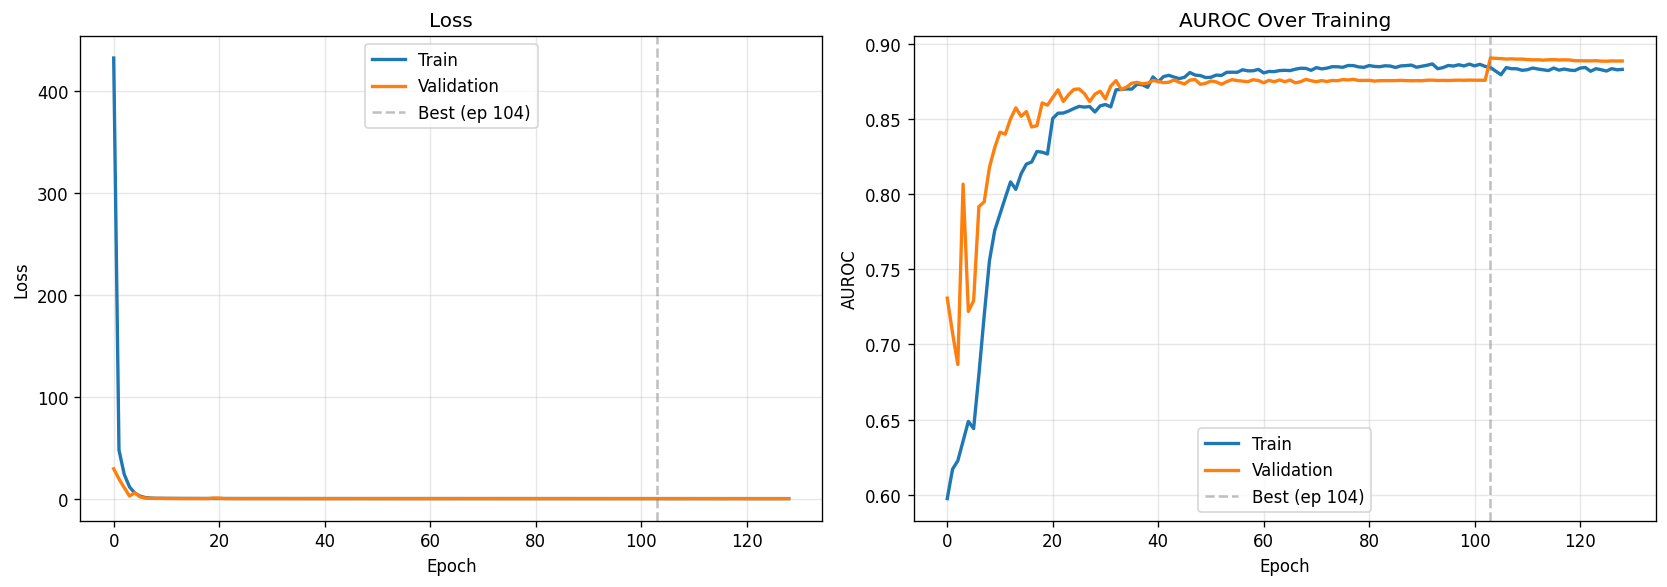

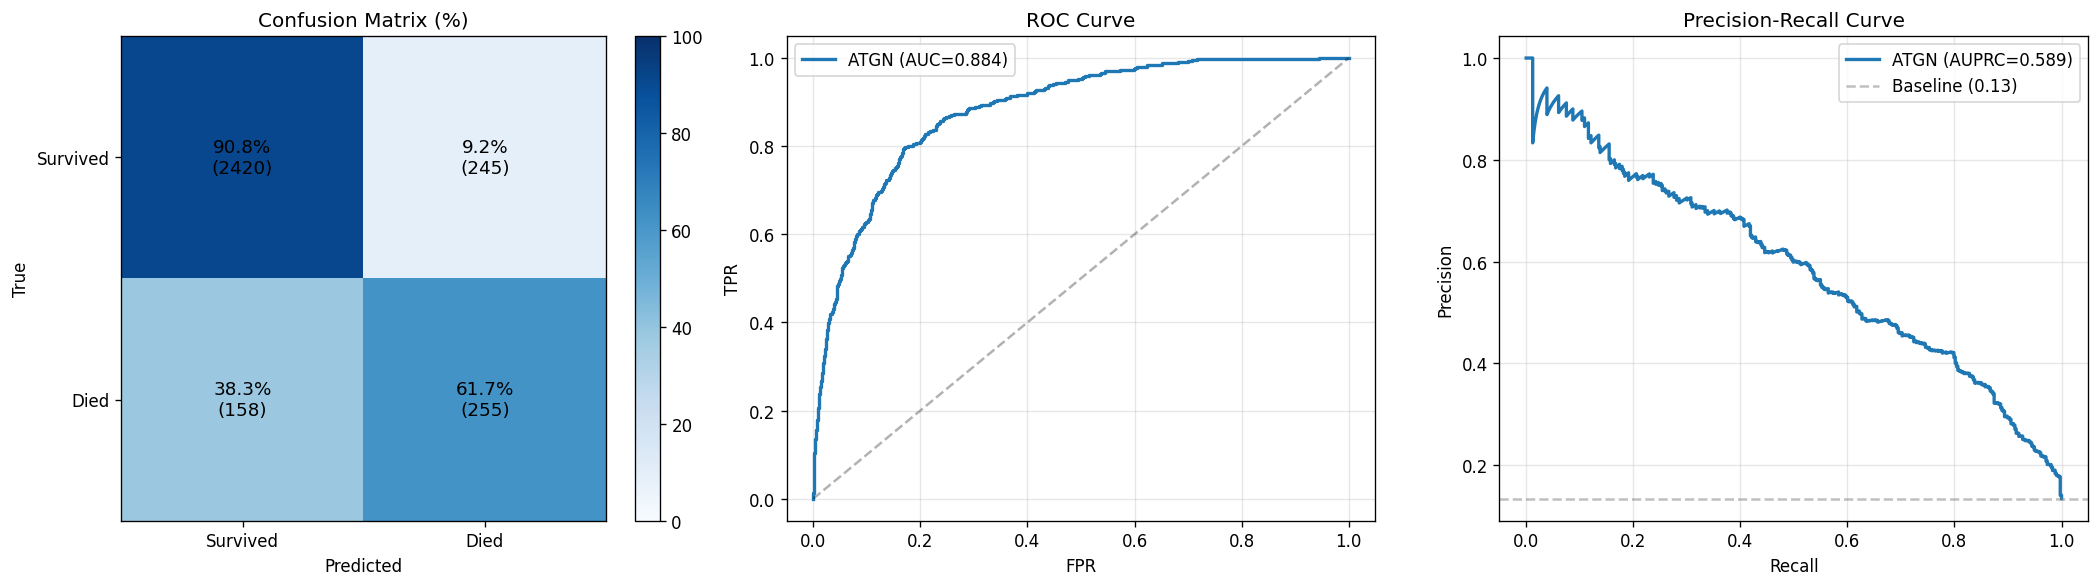

  [saved] exports/confusion_matrix.csv  (2 rows x 2 cols)
  [saved] exports/roc_curve.csv  (500 rows x 3 cols)
  [saved] exports/pr_curve.csv  (3079 rows x 3 cols)


'exports/pr_curve.csv'

In [17]:
test_metrics, test_probs, test_labels = eval_epoch(model, test_loader, loss_fn, DEVICE)

test_auc   = test_metrics['auroc']
test_auprc = test_metrics['auprc']
test_acc   = test_metrics['accuracy']
test_loss  = test_metrics['loss']

print("=" * 60)
print("  FINAL TEST RESULTS (ATGN)")
print("=" * 60)
for k in ['auroc','auprc','f1','brier','sensitivity','specificity','ppv','npv','mcc','kappa','accuracy','loss']:
    print(f"  {k:>12}: {test_metrics[k]:.4f}")
print("=" * 60)

# EXPORT: final metrics, per-patient predictions, training history
export_df(pd.DataFrame([test_metrics]), "test_metrics.csv")
test_pred_df = pd.DataFrame({
    "subject_id": test_subject_ids,
    "label": test_labels.astype(int),
    "prob_raw": test_probs,
})
export_df(test_pred_df, "test_predictions.csv")

hist_cols = {k: v for k, v in history.items() if len(v) > 0}
if hist_cols:
    max_len = max(len(v) for v in hist_cols.values())
    hist_df = pd.DataFrame({k: (v + [np.nan]*(max_len-len(v))) for k, v in hist_cols.items()})
    hist_df.insert(0, "epoch", np.arange(1, max_len + 1))
    export_df(hist_df, "training_history.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
if history.get("train_loss"):
    ax.plot(history["train_loss"], label="Train", linewidth=2)
    ax.plot(history["val_loss"], label="Validation", linewidth=2)
    ax.axvline(best_epoch, color='gray', linestyle='--', alpha=0.5, label=f"Best (ep {best_epoch+1})")
else:
    ax.text(0.5, 0.5, "No training history", ha='center', va='center', transform=ax.transAxes, color='gray')
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_title("Loss"); ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
if history.get("train_auroc"):
    ax.plot(history["train_auroc"], label="Train", linewidth=2)
    ax.plot(history["val_auroc"],   label="Validation", linewidth=2)
    if history.get("test_auroc"):
        ax.plot(history["test_auroc"], label="Test", linewidth=2, alpha=0.6)
    ax.axvline(best_epoch, color='gray', linestyle='--', alpha=0.5, label=f"Best (ep {best_epoch+1})")
else:
    ax.text(0.5, 0.5, "No training history\n(model loaded from checkpoint)",
            ha='center', va='center', transform=ax.transAxes, fontsize=11, color='gray')
ax.set_xlabel("Epoch"); ax.set_ylabel("AUROC"); ax.set_title("AUROC Over Training")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "training_curves.png"), dpi=150, bbox_inches='tight')
plt.show()

from sklearn.metrics import roc_curve, precision_recall_curve
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
cm = confusion_matrix(test_labels, (test_probs > 0.5).astype(int))
cm_pct = cm.astype('float') / cm.sum(axis=1, keepdims=True) * 100
im = ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Survived", "Died"]); ax.set_yticklabels(["Survived", "Died"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion Matrix (%)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm_pct[i,j]:.1f}%\n({cm[i,j]})", ha='center', va='center', fontsize=11)
plt.colorbar(im, ax=ax, fraction=0.046)

ax = axes[1]
fpr, tpr, roc_thr = roc_curve(test_labels, test_probs)
ax.plot(fpr, tpr, linewidth=2, label=f"ATGN (AUC={test_auc:.3f})")
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.set_title("ROC Curve"); ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[2]
prec, rec, pr_thr = precision_recall_curve(test_labels, test_probs)
ax.plot(rec, prec, linewidth=2, label=f"ATGN (AUPRC={test_auprc:.3f})")
ax.axhline(pos_rate, color='gray', linestyle='--', alpha=0.5, label=f"Baseline ({pos_rate:.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-Recall Curve")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "confusion_roc_pr.png"), dpi=150, bbox_inches='tight')
plt.show()

# EXPORT: confusion matrix, ROC, PR
cm_df = pd.DataFrame(cm, index=["true_Survived", "true_Died"],
                     columns=["pred_Survived", "pred_Died"])
export_df(cm_df, "confusion_matrix.csv", index=True)
roc_df = pd.DataFrame({"fpr": fpr, "tpr": tpr,
                       "threshold": np.r_[np.nan, roc_thr] if len(roc_thr) == len(fpr)-1 else roc_thr})
export_df(roc_df, "roc_curve.csv")
pr_df = pd.DataFrame({"recall": rec, "precision": prec,
                      "threshold": np.r_[pr_thr, np.nan] if len(pr_thr) == len(prec)-1 else pr_thr})
export_df(pr_df, "pr_curve.csv")

Brier score -- raw: 0.0938, calibrated: 0.0802
  [saved] exports/test_predictions.csv  (3078 rows x 4 cols)
  [saved] exports/calibration_brier.csv  (1 rows x 2 cols)


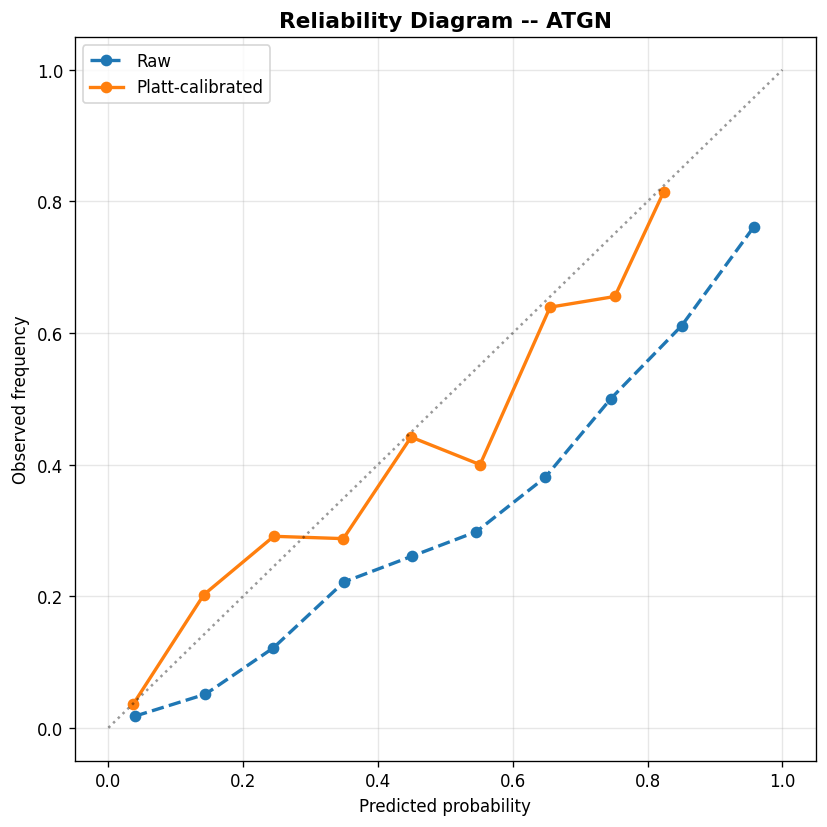

  [saved] exports/reliability_diagram.csv  (19 rows x 3 cols)


'exports/reliability_diagram.csv'

In [18]:
# ================================================================
# Post-hoc Probability Calibration (Platt Scaling), fit on validation
# ================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve

val_metrics, val_probs, val_labels = eval_epoch(model, val_loader, loss_fn, DEVICE)

platt_scaler = LogisticRegression(C=1e10, solver='lbfgs', max_iter=1000)
platt_scaler.fit(val_probs.reshape(-1, 1), val_labels.astype(int))
test_probs_calibrated = platt_scaler.predict_proba(test_probs.reshape(-1, 1))[:, 1]

brier_raw = brier_score_loss(test_labels, test_probs)
brier_cal = brier_score_loss(test_labels, test_probs_calibrated)
print(f"Brier score -- raw: {brier_raw:.4f}, calibrated: {brier_cal:.4f}")

# EXPORT: predictions (raw + calibrated), brier, reliability points
test_pred_df["prob_calibrated"] = test_probs_calibrated
export_df(test_pred_df, "test_predictions.csv")
export_df(pd.DataFrame([{"brier_raw": brier_raw, "brier_calibrated": brier_cal}]),
          "calibration_brier.csv")

fig, ax = plt.subplots(figsize=(7, 7))
reliability_rows = []
for probs_arr, name, ls in [(test_probs, "Raw", "--"),
                            (test_probs_calibrated, "Platt-calibrated", "-")]:
    frac_pos, mean_pred = calibration_curve(test_labels, probs_arr, n_bins=10)
    ax.plot(mean_pred, frac_pos, ls, linewidth=2, marker='o', label=name)
    for mp, fp in zip(mean_pred, frac_pos):
        reliability_rows.append({"variant": name, "mean_predicted": mp, "observed_frequency": fp})
ax.plot([0, 1], [0, 1], 'k:', alpha=0.4)
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency")
ax.set_title("Reliability Diagram -- ATGN", fontsize=13, fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "reliability_diagram.png"), dpi=150, bbox_inches='tight')
plt.show()
export_df(pd.DataFrame(reliability_rows), "reliability_diagram.csv")

### How to read the group-level importance figure

We average each biomarker's total node contribution across test patients,
separately for **died** vs **survived**. Positive pushes the logit toward
mortality; negative pushes away. Because the prediction is `sigma(sum of all
contributions)`, a well-calibrated model shows mostly positive contributions
for died and mostly negative for survived.

- Magnitudes/ordering depend on the trained weights and change after retraining
  (especially after the padding fix). **Read specific numbers from the exported
  `group_importance_by_outcome.csv` / regenerated figure**, not from prose.
- The plot sorts by `|Died - Survived|` to surface the most *discriminative*
  biomarkers, not the largest absolute contributors.
- Multi-biomarker groups (Respiratory) are summarized at the *subset* level
  (Eq. 7). A group's class-mean can be near zero even when per-patient effects
  are large and opposite-signed.
- Caveat: because static features are replicated into every biomarker graph,
  each per-biomarker bar includes a share of the static (age) effect.

In [19]:
# Quick structural assertions
assert hasattr(model, 'gnans'), "Model missing gnans"
assert hasattr(model, 'group_deep_sets'), "Model missing group_deep_sets"
assert len(model.gnans) == len(BIOMARKER_GROUPS), f"Expected {len(BIOMARKER_GROUPS)} GNANs, got {len(model.gnans)}"
assert '0' in model.group_deep_sets, "DeepSet missing for respiratory group (index 0)"

test_gnan = model.gnans[0]
expected_groups = [list(range(NUM_TEMPORAL + 1)), list(range(NUM_TEMPORAL + 1, FEATURE_DIM))]
assert test_gnan.feature_group_indices == expected_groups, \
    f"Feature groups: expected {expected_groups}, got {test_gnan.feature_group_indices}"
assert test_gnan.repr_dim == FEATURE_DIM, f"repr_dim: expected {FEATURE_DIM}, got {test_gnan.repr_dim}"

dummy_dist = torch.tensor([[1.0]]).to(DEVICE)
rho_out = test_gnan.rho(dummy_dist)
assert rho_out.shape == (1, 1), f"rho should map R->R, got shape {rho_out.shape}"

import inspect
ds_source = inspect.getsource(DeepSet.forward)
assert 'torch.sum' in ds_source or 'sum(' in ds_source, "DeepSet should use SUM aggregation per paper"
print("All structural assertions passed (ATGN).")

All structural assertions passed (ATGN).


## 9. Interpretability Analysis

A key advantage of ATGN is **built-in additive interpretability**.

### Node-Level Importance (Eq. 6)
$$\text{TotalContribution}(j) = \sum_{l=1}^{K} [\mathbf{h}_j]_{F_l}$$

### Graph-Level Importance
$$\text{TotalContribution}(G) = \sum_{v \in G} \text{TotalContribution}(v)$$

> Node-level attribution is exact only for *singleton* groups. For multi-biomarker
> groups (Respiratory) the DeepSet readout is nonlinear with a bias, so we report
> those at the *subset* level (Eq. 7). All attribution functions run with
> `batch_dim=1`, which never triggers the padding path -- so attributions are on
> the corrected, fully-decomposable path.

In [20]:
@torch.no_grad()
def plot_rho_heatmap(model, patient_data, device, biomarker="GCS",
                     raw_patient=None, subject_id=None, figsize=(10, 8), save=True):
    """Heatmap of learned temporal attention rho(Delta) for one biomarker graph.
    Rows = source node w, cols = target node j. Saves the matrix to
    exports/rho_<subject>_<biomarker>.csv when save and subject_id are given."""
    model.eval()
    graph_dict, label = patient_data
    if biomarker not in graph_dict:
        print(f"{biomarker} not present for this patient.")
        return

    gi = model.biomarker_to_gnan[biomarker]
    gnan = model.gnans[gi]
    nf, dm = graph_dict[biomarker]
    x = nf.to(device); dist = dm.to(device)
    bvec = torch.zeros(x.shape[0], dtype=torch.long, device=device)
    _, _, rho_w = gnan(x, dist, bvec, return_node_embeddings=True, return_rho_weights=True)
    rho_np = rho_w.cpu().numpy()

    if raw_patient and biomarker in raw_patient['timeseries']:
        time_vals = [m[0] for m in sorted(raw_patient['timeseries'][biomarker], key=lambda x: x[0])]
    else:
        time_vals = list(range(rho_np.shape[0]))
    times = [f"{t:.1f}h" if isinstance(t, float) else str(t) for t in time_vals]

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(rho_np, cmap='viridis', aspect='auto')
    ax.set_xlabel("Target node j"); ax.set_ylabel("Source node w")
    sid_str = f" (subj {subject_id})" if subject_id is not None else ""
    ax.set_title(f"rho(Delta) Temporal Attention -- {biomarker}{sid_str}", fontsize=13, fontweight='bold')
    ax.set_xticks(range(len(times))); ax.set_xticklabels(times, rotation=90, fontsize=6)
    ax.set_yticks(range(len(times))); ax.set_yticklabels(times, fontsize=6)
    plt.colorbar(im, ax=ax, label="rho weight")
    plt.tight_layout()

    if save and subject_id is not None:
        rho_df = pd.DataFrame(rho_np,
                              index=[f"src_{t}" for t in time_vals],
                              columns=[f"tgt_{t}" for t in time_vals])
        rho_df.insert(0, "subject_id", subject_id)
        rho_df.insert(1, "biomarker", biomarker)
        export_df(rho_df, f"rho_{subject_id}_{biomarker}.csv", index=True)
        plt.savefig(os.path.join(EXPORT_DIR, f"rho_{subject_id}_{biomarker}.png"),
                    dpi=150, bbox_inches='tight')
    plt.show()
    return fig

In [21]:
@torch.no_grad()
def compute_attributions_correct(model, patient_data, device, raw_patient=None):
    """Singletons -> exact node-level (Eq. 6); multi-graph groups -> subset (Eq. 7).
    Returns (node_details, subset_details, label)."""
    model.eval()
    graph_dict, label = patient_data

    inputs = {}
    for biom_name, (nf, dm) in graph_dict.items():
        inputs[biom_name] = {
            'x_batch': nf, 'dist_batch': dm,
            'batch_vector': torch.zeros(nf.shape[0], dtype=torch.long),
        }
    group_outputs = model(inputs, batch_dim=1, return_group_outputs=True)  # [num_groups,1,repr]

    node_details = {}
    subset_details = {}
    for gi, group in enumerate(model.biomarker_groups):
        if len(group) == 1:
            biom = group[0]
            if biom not in graph_dict:
                continue
            gnan = model.gnans[gi]
            nf, dm = graph_dict[biom]
            x = nf.to(device); dist = dm.to(device)
            bvec = torch.zeros(x.shape[0], dtype=torch.long, device=device)
            _, node_emb = gnan(x, dist, bvec, return_node_embeddings=True)
            node_details[biom] = {
                'contributions': node_emb.sum(dim=-1).cpu().numpy(),
                'times': (np.array([m[0] for m in sorted(raw_patient['timeseries'][biom], key=lambda x: x[0])])
                          if raw_patient else dm.numpy()[:, 0]),
                'group_idx': gi,
            }
        else:
            group_contribution = group_outputs[gi, 0, :].sum().item()
            group_name = GROUP_NAMES[gi]
            members_present = [b for b in group if b in graph_dict]
            subset_details[group_name] = {
                'contribution': group_contribution,
                'members': group, 'members_present': members_present,
            }
    return node_details, subset_details, label.item()

In [22]:
@torch.no_grad()
def compute_population_importance_correct(model, dataset, device, raw_patients=None,
                                          max_samples=200, save_long=None):
    """Class-averaged importance. Singletons: sum of node contributions (Eq. 6);
    multi-graph: subset contribution (Eq. 7). Optionally writes a per-patient
    long-form CSV (subject_id, group, contribution, label)."""
    model.eval()
    pos_imp, neg_imp = defaultdict(list), defaultdict(list)
    long_rows = []
    for idx in range(min(len(dataset), max_samples)):
        rp = raw_patients[idx] if raw_patients is not None else None
        node_details, subset_details, label = compute_attributions_correct(
            model, dataset[idx], device, raw_patient=rp)
        target = pos_imp if label == 1 else neg_imp
        sid = rp['patient_id'] if rp is not None else idx
        for biom, d in node_details.items():
            val = float(np.sum(d['contributions']))
            target[biom].append(val)
            long_rows.append({"subject_id": sid, "group": biom, "contribution": val, "label": int(label)})
        for group_name, d in subset_details.items():
            target[group_name].append(d['contribution'])
            long_rows.append({"subject_id": sid, "group": group_name,
                              "contribution": d['contribution'], "label": int(label)})
    if save_long is not None and raw_patients is not None:
        export_df(pd.DataFrame(long_rows), save_long)
    return ({b: np.mean(v) for b, v in pos_imp.items()},
            {b: np.mean(v) for b, v in neg_imp.items()})

In [23]:
def plot_node_attribution_figure2(model, patient_data, device, top_k=12, title=None,
                                  raw_patient=None, subject_id=None, save=True):
    """Hour-binned node-contribution heatmap (biomarkers x hours 1H-48H).
    RdBu_r: red pushes toward mortality, blue away. When save and subject_id are
    given, writes the FULL matrix (all rows) in both wide and long form."""
    import seaborn as sns
    node_details, subset_details, label = compute_attributions_correct(
        model, patient_data, device, raw_patient=raw_patient)
    if not node_details and not subset_details:
        print("No biomarker data for this patient.")
        return

    n_hours = 48
    status = "DIED" if label == 1 else "SURVIVED"

    all_names, all_grids = [], []
    for biom, d in node_details.items():
        row = np.zeros(n_hours, dtype=np.float32)
        for t, c in zip(d['times'], d['contributions']):
            h = int(np.clip(np.floor(t), 0, n_hours - 1))
            row[h] += c
        all_names.append(biom); all_grids.append(row)

    for group_name, info in subset_details.items():
        contrib = info['contribution']
        member_hours = set()
        for b in info['members_present']:
            if b in node_details:
                for t in node_details[b]['times']:
                    member_hours.add(int(np.clip(np.floor(t), 0, n_hours - 1)))
        row = np.zeros(n_hours, dtype=np.float32)
        if member_hours:
            per_hour = contrib / len(member_hours)
            for h in member_hours:
                row[h] = per_hour
        else:
            row[0] = contrib
        all_names.append(f"* {group_name}"); all_grids.append(row)

    if not all_names:
        print("No data to plot."); return

    full_grid = np.array(all_grids)  # [n_rows, 48]

    if save and subject_id is not None:
        hour_cols = [f"{h+1}H" for h in range(n_hours)]
        wide = pd.DataFrame(full_grid, index=all_names, columns=hour_cols)
        wide.index.name = "biomarker"
        wide_out = wide.reset_index()
        wide_out.insert(0, "subject_id", subject_id)
        wide_out.insert(1, "outcome", status)
        export_df(wide_out, f"node_attribution_{subject_id}_{status}_wide.csv")
        long_rows = []
        for name, grid_row in zip(all_names, full_grid):
            for h in range(n_hours):
                if grid_row[h] != 0.0:
                    long_rows.append({"subject_id": subject_id, "outcome": status,
                                      "biomarker": name, "hour": h + 1,
                                      "contribution": float(grid_row[h])})
        export_df(pd.DataFrame(long_rows), f"node_attribution_{subject_id}_{status}_long.csv")

    total_abs = np.abs(full_grid).sum(axis=1)
    order = np.argsort(total_abs)[::-1][:top_k]
    grid = full_grid[order]
    names = [all_names[i] for i in order]
    vmax = np.abs(grid).max(); vmin = -vmax

    fig_h = max(4, len(names) * 0.55 + 2)
    fig, ax = plt.subplots(figsize=(18, fig_h))
    sns.heatmap(grid, cmap="RdBu_r", center=0, vmin=vmin, vmax=vmax,
                linewidths=0.4, linecolor='white',
                cbar_kws={"shrink": 0.7, "label": "Contribution"}, ax=ax,
                xticklabels=[f"{h+1}H" for h in range(n_hours)], yticklabels=names)
    ax.xaxis.tick_top(); ax.xaxis.set_label_position('top')
    plt.setp(ax.get_xticklabels(), rotation=90, ha='center', fontsize=7)
    plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)
    ax.tick_params(axis='both', which='both', length=0)
    ax.set_title(title or f"Node-Level Attribution Heatmap -- Patient outcome: {status}",
                 fontsize=14, fontweight='bold', pad=55)
    ax.set_xlabel(""); ax.set_ylabel("")
    cbar = ax.collections[0].colorbar; cbar.ax.tick_params(length=0); cbar.outline.set_visible(False)
    plt.tight_layout()
    if save and subject_id is not None:
        plt.savefig(os.path.join(EXPORT_DIR, f"node_attribution_{subject_id}_{status}.png"),
                    dpi=150, bbox_inches='tight')
    plt.show()
    return fig

In [24]:
def print_patient_raw_hourly(patient, biomarkers_to_show=None, n_hours=48, save=True):
    """Print raw (un-normalized) hourly-binned values and, if save, write them to
    exports/patient_<subject>_hourly.csv (biomarker rows x hour cols; NA empties)."""
    ts = patient['timeseries']
    if biomarkers_to_show is None:
        biomarkers_to_show = sorted(ts.keys())
    sid = patient['patient_id']
    print(f"\nPatient {sid} | Label: {'DIED' if patient['label'] else 'SURVIVED'} | "
          f"Age: {patient['static']['age']:.0f} | Gender: {'M' if patient['static']['gender'] else 'F'}")
    print("-" * 120)

    export_rows = {}
    for biom in biomarkers_to_show:
        if biom not in ts or len(ts[biom]) < 1:
            continue
        unit = BIOMARKER_CONFIG.get(biom, {}).get('unit', '?')
        hour_bins = {}
        for t, v in sorted(ts[biom], key=lambda x: x[0]):
            hb = int(np.clip(np.floor(t), 0, n_hours - 1))
            hour_bins[hb] = v
        vals, numeric_row = [], []
        for h in range(n_hours):
            if h in hour_bins:
                v = hour_bins[h]
                vals.append(f"{v:.1f}" if abs(v) < 1000 else f"{v:.0f}")
                numeric_row.append(v)
            else:
                vals.append("NA"); numeric_row.append(np.nan)
        print(f"  {biom:>15} ({unit:>8}): [{', '.join(vals)}]")
        export_rows[biom] = numeric_row
    print()
    if save and export_rows:
        df = pd.DataFrame.from_dict(export_rows, orient='index',
                                    columns=[f"{h+1}H" for h in range(n_hours)])
        df.index.name = "biomarker"
        out = df.reset_index()
        out.insert(0, "subject_id", sid)
        out.insert(1, "label", patient['label'])
        export_df(out, f"patient_{sid}_hourly.csv")
    return export_rows

In [25]:
# --- Candidate pools (once) ---
mortality_indices = [i for i in range(len(test_dataset))
                     if test_dataset[i][1].item() == 1 and len(test_dataset[i][0]) >= 8]
survival_indices  = [i for i in range(len(test_dataset))
                     if test_dataset[i][1].item() == 0 and len(test_dataset[i][0]) >= 8]
print(f"Eligible patients -- Mortality: {len(mortality_indices)}, Survival: {len(survival_indices)}")

# DETERMINISTIC case-study selection: pick ONCE with a seeded RNG and reuse the
# SAME indices for both the node-attribution and rho-heatmap figures so every
# figure/CSV refers to the same patients (previously they re-rolled).
_case_rng = random.Random(SEED)
i_mort = _case_rng.choice(mortality_indices)
i_surv = _case_rng.choice(survival_indices)
mort_subject_id = test_patients[i_mort]['patient_id']
surv_subject_id = test_patients[i_surv]['patient_id']
print(f"Case-study mortality: test idx {i_mort} (subject {mort_subject_id})")
print(f"Case-study survival:  test idx {i_surv} (subject {surv_subject_id})")

Eligible patients -- Mortality: 413, Survival: 2665
Case-study mortality: test idx 2452 (subject 18096149)
Case-study survival:  test idx 544 (subject 13394639)


  [saved] exports/global_node_attributions.csv  (108936 rows x 7 cols)


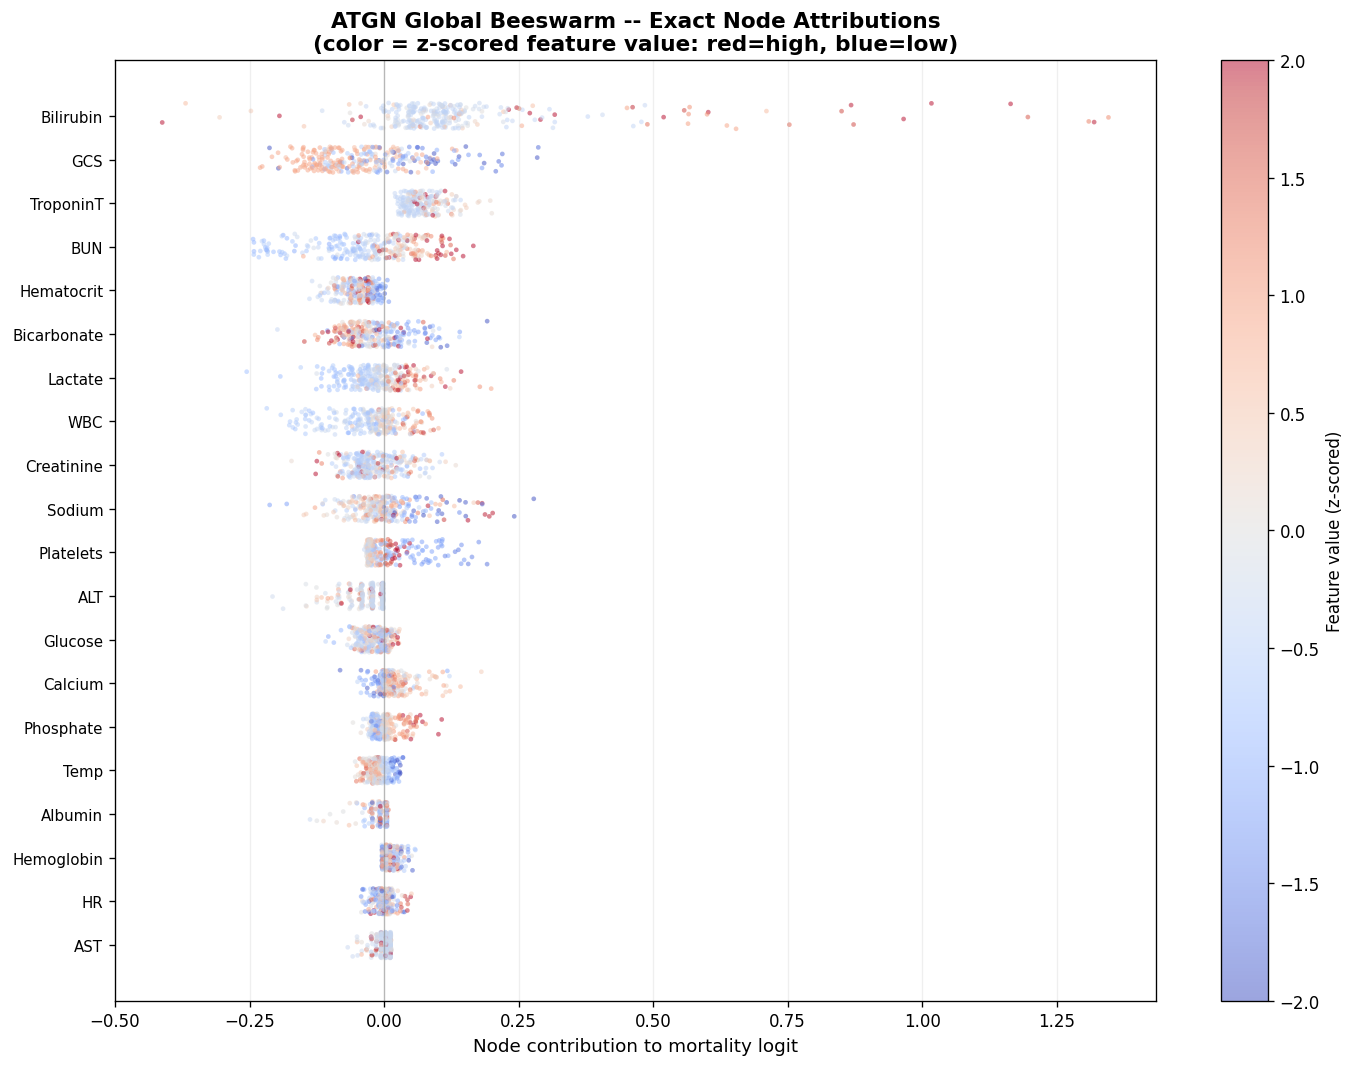

In [26]:
# ================================================================
# ATGN Global Beeswarm from Exact Node Attributions
# ================================================================
@torch.no_grad()
def collect_global_attributions(model, dataset, raw_patients, device,
                                biomarker_stats, max_samples=500):
    """Collect per-node (subject_id, biomarker, node_idx, time, z-value,
    contribution, label) across patients (singletons only -- exact)."""
    records = []
    for idx in range(min(len(dataset), max_samples)):
        rp = raw_patients[idx]
        sid = rp['patient_id']
        node_det, _, label = compute_attributions_correct(model, dataset[idx], device, raw_patient=rp)
        for biom, d in node_det.items():
            nf = dataset[idx][0][biom][0]
            z_vals = nf[:, 0].numpy()
            contribs = d['contributions']
            times = d['times']
            for node_idx, (zv, c, t) in enumerate(zip(z_vals, contribs, times)):
                records.append((sid, biom, node_idx, float(t), float(zv), float(c), int(label)))
    return pd.DataFrame(records, columns=['subject_id', 'biomarker', 'node_idx',
                                          'time_hours', 'feature_value', 'contribution', 'label'])

print("Collecting global attributions for beeswarm...")
bee_df = collect_global_attributions(model, test_dataset, test_patients_binned, DEVICE,
                                     BIOMARKER_STATS, max_samples=400)
export_df(bee_df, "global_node_attributions.csv")

biom_order = (bee_df.groupby('biomarker')['contribution']
              .apply(lambda x: np.abs(x).mean()).sort_values(ascending=False).head(20).index.tolist())

fig, ax = plt.subplots(figsize=(12, 9))
for rank, biom in enumerate(reversed(biom_order)):
    sub = bee_df[bee_df['biomarker'] == biom].sample(
        n=min(300, len(bee_df[bee_df['biomarker'] == biom])), random_state=SEED)
    y_jitter = rank + np.random.uniform(-0.3, 0.3, size=len(sub))
    sc = ax.scatter(sub['contribution'], y_jitter, c=sub['feature_value'], cmap='coolwarm',
                    s=8, alpha=0.5, vmin=-2, vmax=2, edgecolors='none')
ax.set_yticks(range(len(biom_order))); ax.set_yticklabels(list(reversed(biom_order)), fontsize=9)
ax.set_xlabel("Node contribution to mortality logit", fontsize=11)
ax.axvline(0, color='gray', linewidth=0.8, alpha=0.5)
ax.set_title("ATGN Global Beeswarm -- Exact Node Attributions\n"
             "(color = z-scored feature value: red=high, blue=low)", fontsize=13, fontweight='bold')
plt.colorbar(sc, ax=ax, label="Feature value (z-scored)")
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "atgn_beeswarm.png"), dpi=150, bbox_inches='tight')
plt.show()

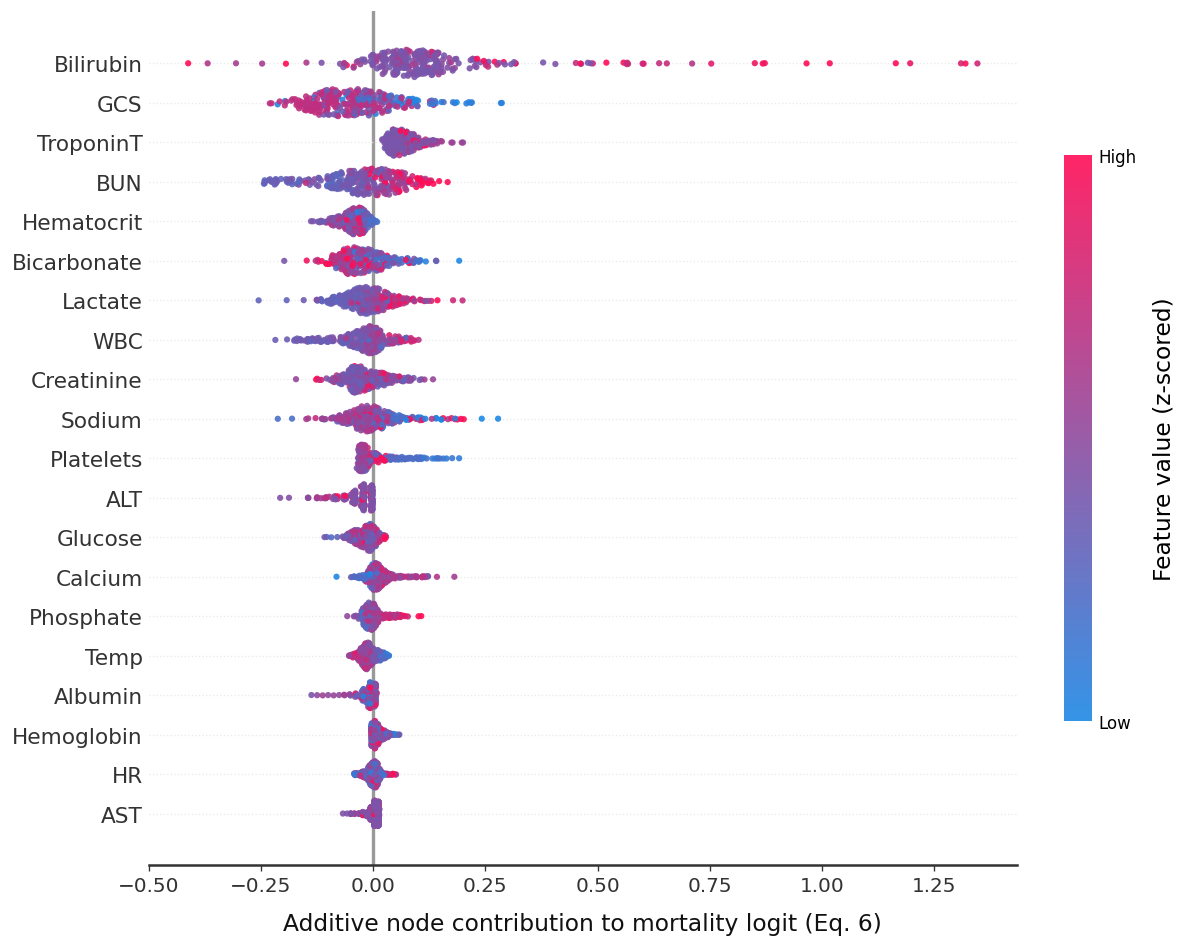

In [27]:
# Styled beeswarm. NOTE: these are the model's exact ADDITIVE node
# contributions (Eq. 6), NOT Shapley values -- labeled accordingly.
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde

biom_order = (bee_df.groupby('biomarker')['contribution']
              .apply(lambda x: np.abs(x).mean()).sort_values(ascending=False).head(20).index.tolist())
beeswarm_cmap = LinearSegmentedColormap.from_list("atgn_red_blue", ["#1E88E5", "#ff0d57"])

fig, ax = plt.subplots(figsize=(10, 8))
for rank, biom in enumerate(reversed(biom_order)):
    sub = bee_df[bee_df['biomarker'] == biom].sample(
        n=min(300, len(bee_df[bee_df['biomarker'] == biom])), random_state=SEED)
    x_vals = sub['contribution'].values
    c_vals = sub['feature_value'].values
    if len(x_vals) > 5:
        x_noisy = x_vals + np.random.normal(0, 1e-6, size=len(x_vals))
        try:
            kde = gaussian_kde(x_noisy)
            density = kde(x_noisy)
            density_scaled = (density / density.max()) * 0.35
            y_jitter = rank + np.random.uniform(-density_scaled, density_scaled, size=len(x_vals))
        except Exception:
            y_jitter = rank + np.random.uniform(-0.3, 0.3, size=len(x_vals))
    else:
        y_jitter = rank + np.random.uniform(-0.1, 0.1, size=len(x_vals))
    sc = ax.scatter(x_vals, y_jitter, c=c_vals, cmap=beeswarm_cmap, s=14, alpha=0.9,
                    vmin=-2, vmax=2, edgecolors='none', zorder=2)

ax.set_yticks(range(len(biom_order))); ax.set_yticklabels(list(reversed(biom_order)), fontsize=13, color='#333333')
ax.tick_params(axis='y', length=0)
ax.yaxis.grid(True, linestyle='dotted', color='#e5e5e5', zorder=0, alpha=0.8)
ax.set_xlabel("Additive node contribution to mortality logit (Eq. 6)", fontsize=14, labelpad=10, color='#111111')
ax.tick_params(axis='x', labelsize=12, colors='#333333'); ax.xaxis.grid(False)
ax.axvline(0, color='#999999', linewidth=2, zorder=1)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False); ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.5); ax.spines['bottom'].set_color('#333333')
cbar = plt.colorbar(sc, ax=ax, fraction=0.03, pad=0.05)
cbar.set_label("Feature value (z-scored)", fontsize=14, labelpad=10)
cbar.set_ticks([-2, 2]); cbar.set_ticklabels(['Low', 'High']); cbar.outline.set_visible(False)
cbar.ax.tick_params(size=0)
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "atgn_beeswarm_styled.png"), dpi=300, bbox_inches='tight')
plt.show()

  [saved] exports/group_importance_per_patient.csv  (68473 rows x 4 cols)
  [saved] exports/group_importance_by_outcome.csv  (27 rows x 4 cols)


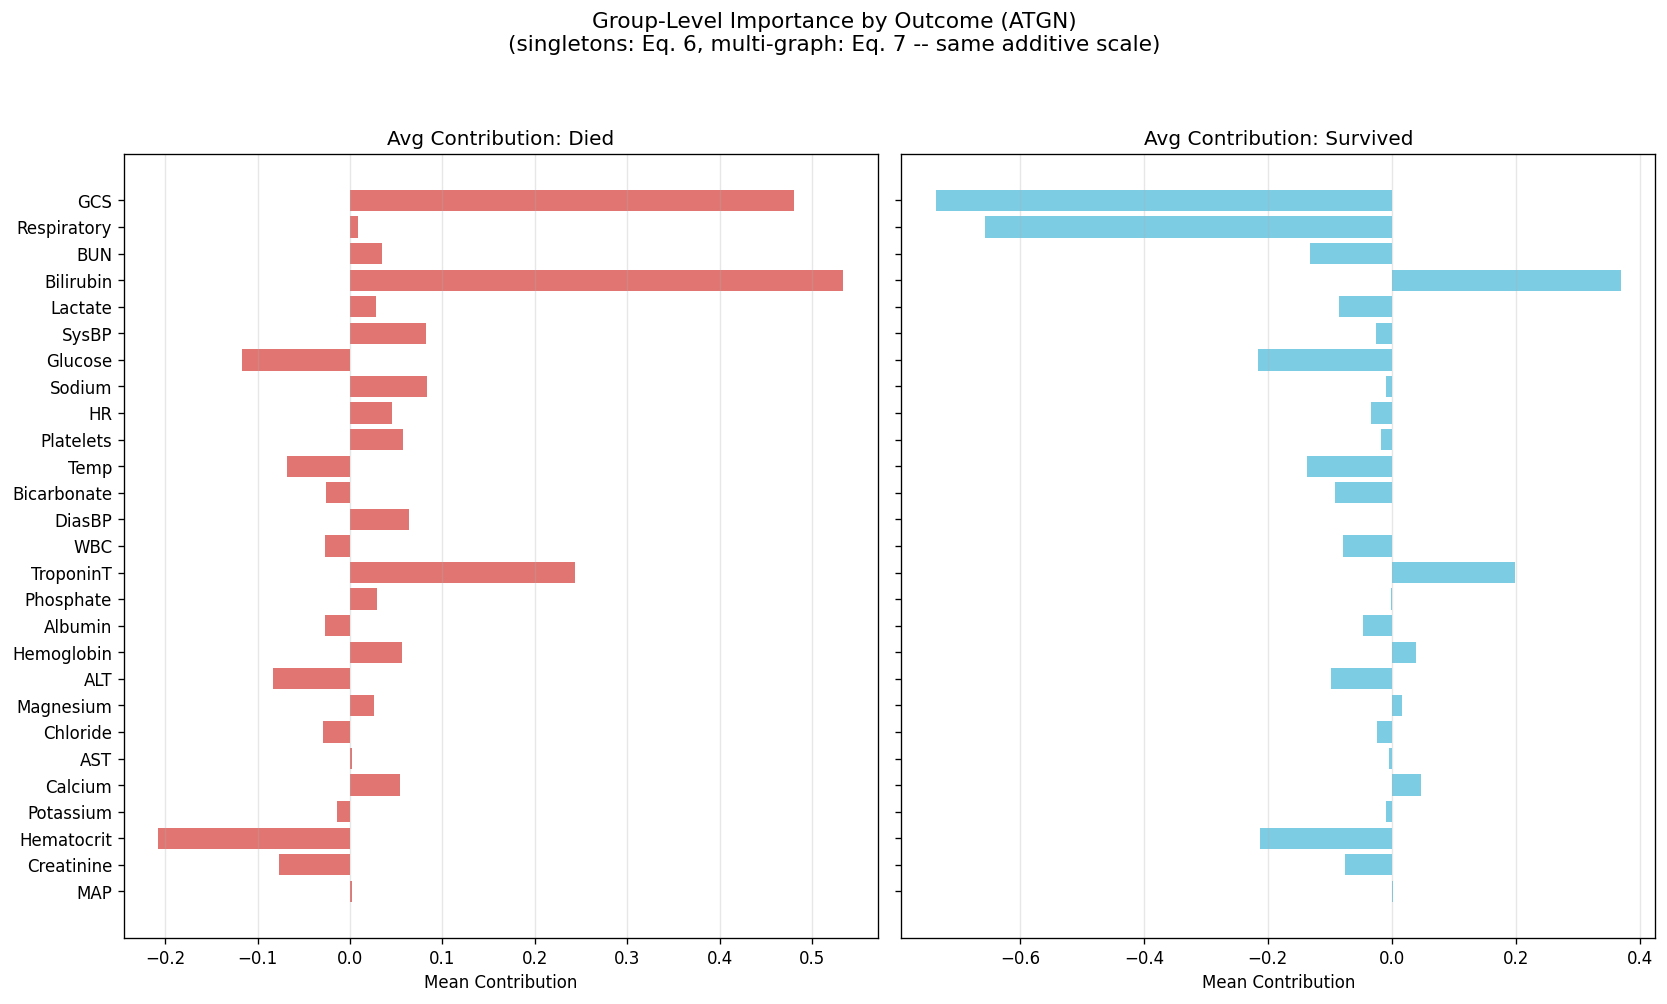

In [28]:
pos_imp, neg_imp = compute_population_importance_correct(
    model, test_dataset, DEVICE, raw_patients=test_patients_binned,
    max_samples=len(test_dataset), save_long="group_importance_per_patient.csv")

all_groups = sorted(set(pos_imp.keys()) | set(neg_imp.keys()))
df_imp = pd.DataFrame({
    'Biomarker': all_groups,
    'Died': [pos_imp.get(b, 0) for b in all_groups],
    'Survived': [neg_imp.get(b, 0) for b in all_groups],
})
df_imp['AbsDiff'] = abs(df_imp['Died'] - df_imp['Survived'])
df_imp = df_imp.sort_values('AbsDiff', ascending=True)

# EXPORT: class-averaged group importance (the plotted values)
export_df(df_imp, "group_importance_by_outcome.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
axes[0].barh(df_imp['Biomarker'], df_imp['Died'], color='#d9534f', alpha=0.8)
axes[0].set_title("Avg Contribution: Died", fontsize=12)
axes[0].set_xlabel("Mean Contribution"); axes[0].grid(axis='x', alpha=0.3)
axes[1].barh(df_imp['Biomarker'], df_imp['Survived'], color='#5bc0de', alpha=0.8)
axes[1].set_title("Avg Contribution: Survived", fontsize=12)
axes[1].set_xlabel("Mean Contribution"); axes[1].grid(axis='x', alpha=0.3)
plt.suptitle("Group-Level Importance by Outcome (ATGN)\n"
             "(singletons: Eq. 6, multi-graph: Eq. 7 -- same additive scale)", fontsize=13, y=1.04)
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "group_importance_by_outcome.png"), dpi=150, bbox_inches='tight')
plt.show()

NODE-LEVEL ATTRIBUTION -- MORTALITY CASE (test idx 2452, subject 18096149)
  [saved] exports/node_attribution_18096149_DIED_wide.csv  (25 rows x 51 cols)
  [saved] exports/node_attribution_18096149_DIED_long.csv  (317 rows x 5 cols)


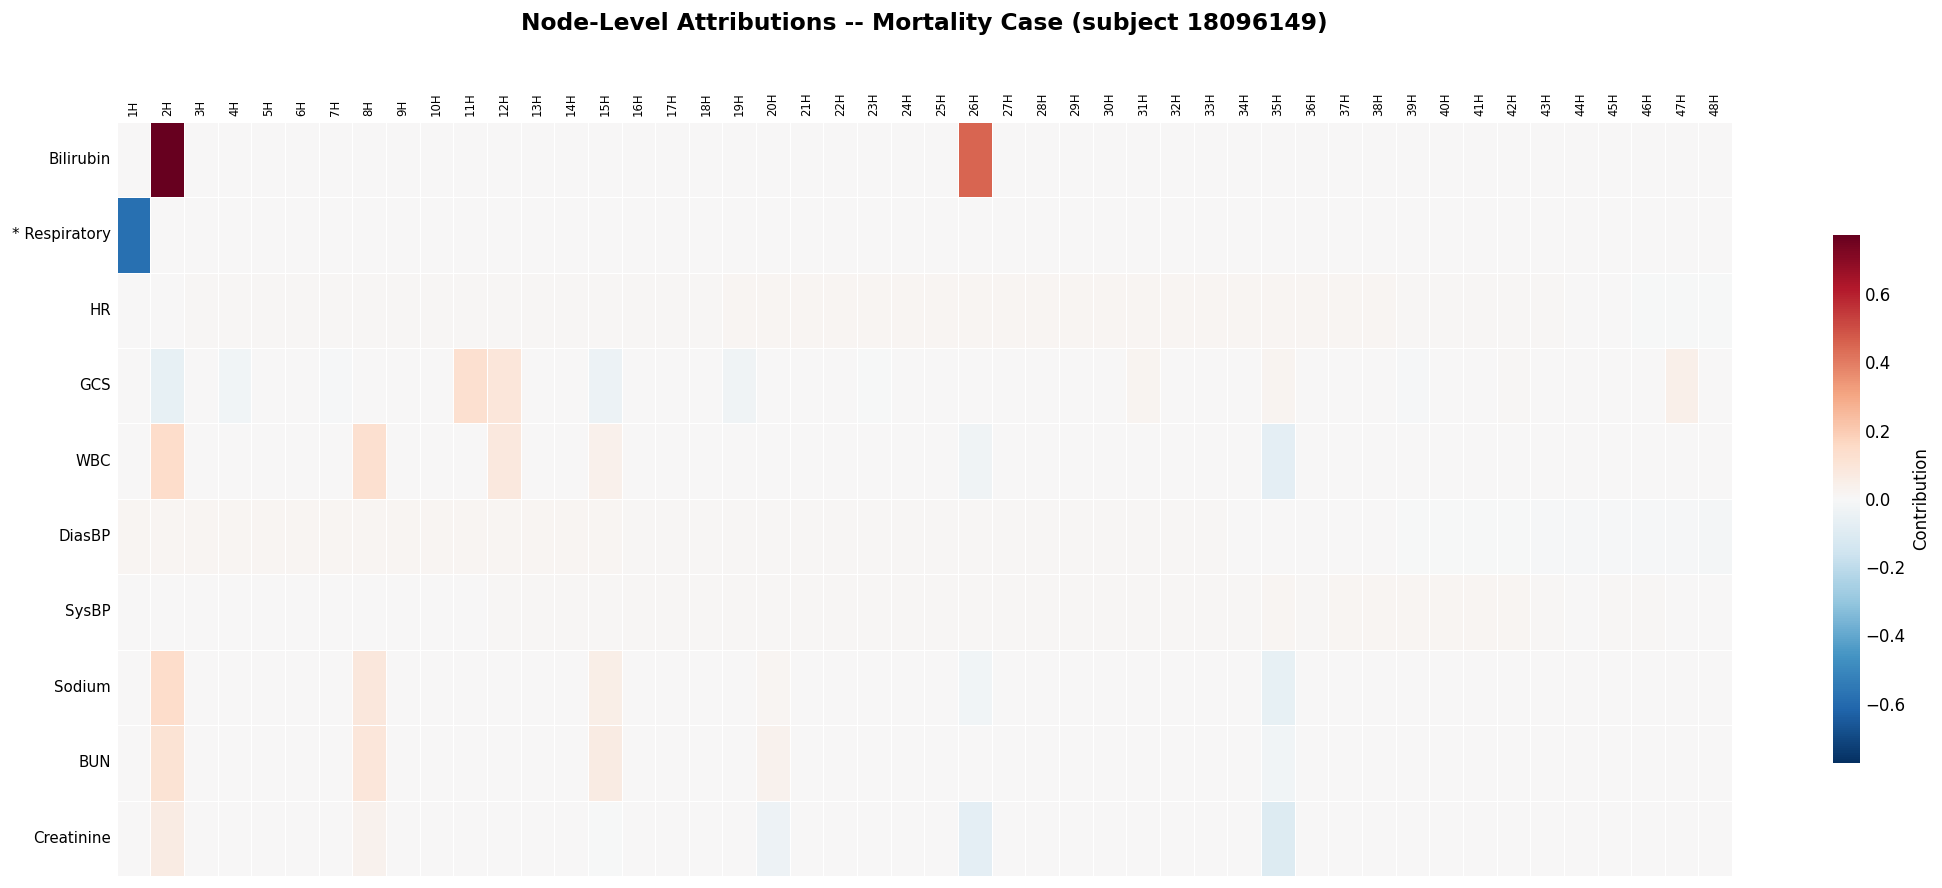


Patient 18096149 | Label: DIED | Age: 63 | Gender: M
------------------------------------------------------------------------------------------------------------------------
               HR (     bpm): [97.0, 100.0, 95.0, 100.0, 96.0, 98.0, 101.0, 109.0, 107.0, 115.0, 98.0, 96.0, 97.0, 99.0, 99.0, 96.0, 93.0, 95.0, 97.0, 94.0, 93.0, 93.0, 92.0, 94.0, 95.0, 94.0, 98.0, 102.0, 97.0, 102.0, 96.0, 99.0, 101.0, 95.0, 95.0, 101.0, 113.0, 108.0, 124.0, 106.0, 107.0, 104.0, 105.0, 130.0, 115.0, 113.0, 115.0, 110.0]
            SysBP (    mmHg): [97.0, 96.0, 95.0, 103.0, 92.0, 104.0, 102.0, 105.0, 108.0, 118.0, 103.0, 105.0, 119.0, 110.0, 111.0, 110.0, 103.0, 110.0, 104.0, 113.0, 117.0, 111.0, 107.0, 109.0, 108.0, 107.0, 108.0, 119.0, 106.0, 111.0, 111.0, 112.0, 110.0, 106.0, 102.0, 109.0, 101.0, 97.0, 99.0, 100.0, 97.0, 92.0, 94.0, 108.0, 92.0, 88.0, 94.0, 92.0]
           DiasBP (    mmHg): [43.0, 45.0, 39.0, 46.0, 35.0, 42.0, 45.0, 53.0, 50.0, 49.0, 43.0, 40.0, 47.0, 45.0, 45.0, 42.0, 38.

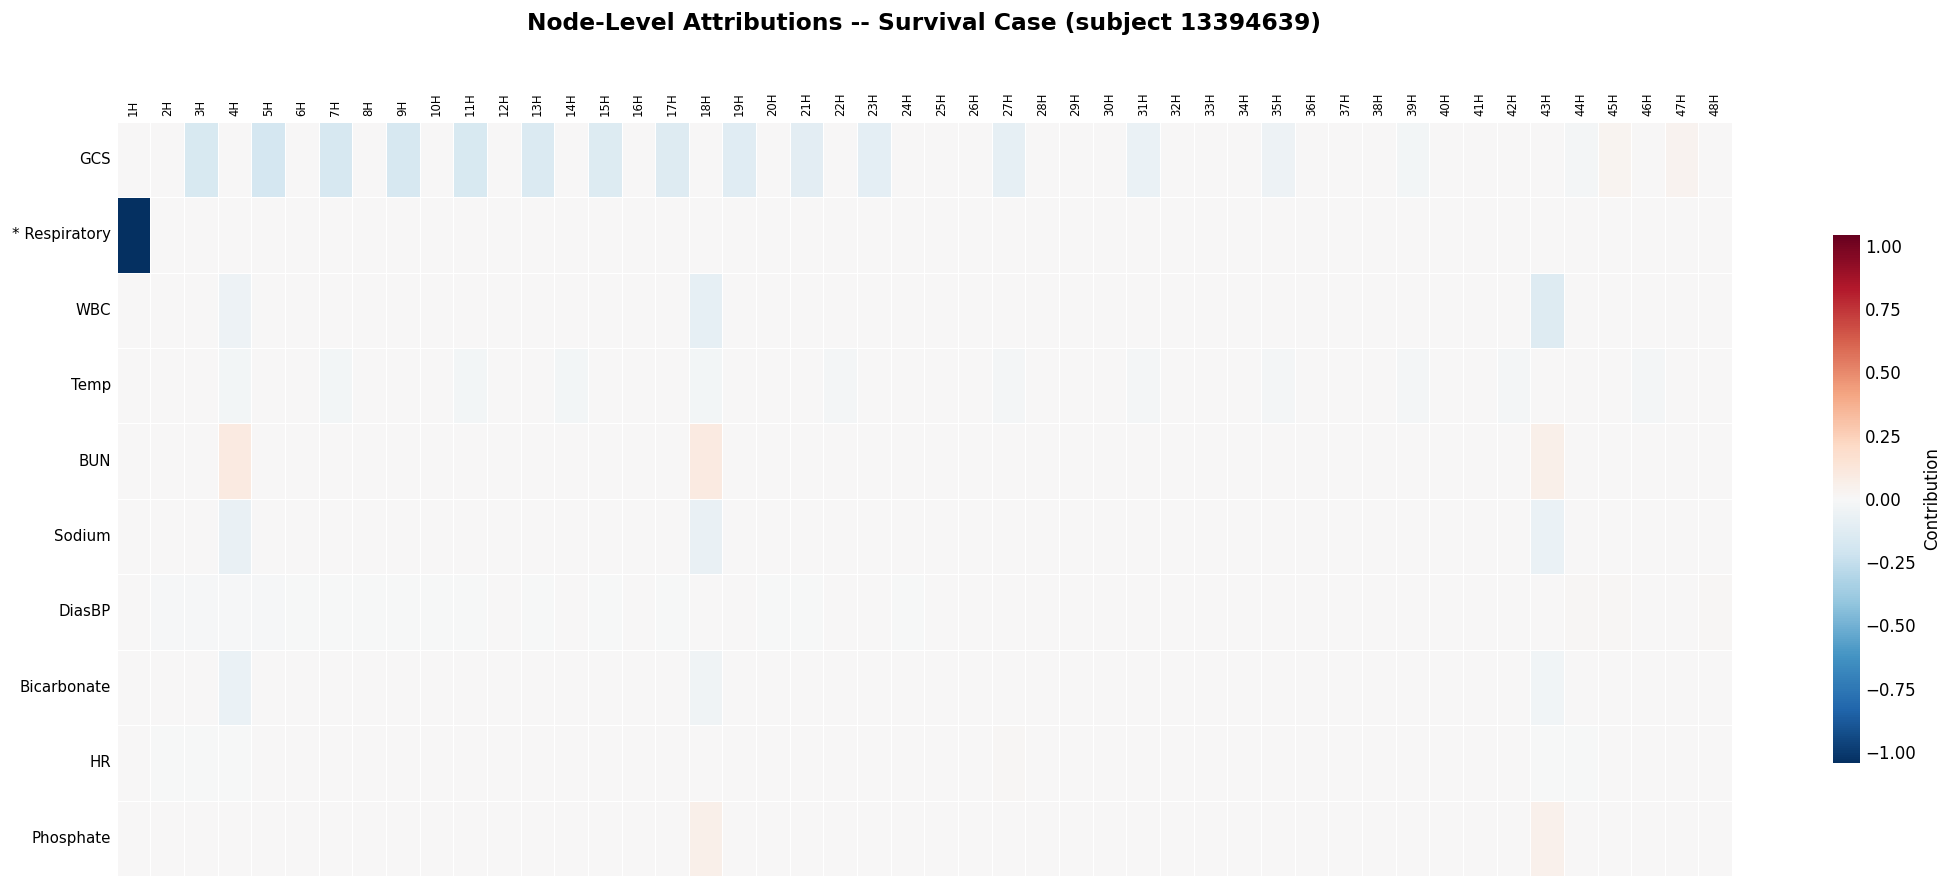


Patient 13394639 | Label: SURVIVED | Age: 41 | Gender: F
------------------------------------------------------------------------------------------------------------------------
               HR (     bpm): [NA, 89.0, 105.0, 93.0, 111.0, 90.0, 94.0, 95.0, 99.0, 87.0, 94.0, NA, 102.0, NA, 94.0, NA, 89.0, NA, 101.0, 105.0, 100.0, 81.0, 83.0, 90.0, 88.0, 85.0, 84.0, NA, 109.0, 107.0, 109.0, NA, NA, NA, 110.0, NA, 107.0, NA, 114.0, NA, 113.0, 120.0, 126.0, 106.0, 97.0, 93.0, 93.0, 90.0]
            SysBP (    mmHg): [NA, 132.0, 125.0, 133.0, 131.0, 132.0, 126.0, 128.0, 127.0, 140.0, 122.0, NA, 119.0, NA, 119.0, NA, 127.0, NA, NA, 125.0, 135.0, NA, NA, 128.0, 78.0, NA, 144.0, NA, 140.0, NA, 127.0, NA, NA, NA, NA, 121.0, 114.0, NA, 124.0, NA, 129.0, NA, NA, 128.0, 112.0, NA, NA, 112.0]
           DiasBP (    mmHg): [NA, 98.0, 92.0, 91.0, 94.0, 89.0, 86.0, 89.0, 85.0, 94.0, 80.0, NA, 81.0, NA, 75.0, NA, 83.0, NA, NA, 92.0, 94.0, NA, NA, 89.0, 14.0, NA, 97.0, NA, 97.0, NA, 97.0, NA, NA, NA, 

{'HR': [nan,
  89.0,
  105.0,
  93.0,
  111.0,
  90.0,
  94.0,
  95.0,
  99.0,
  87.0,
  94.0,
  nan,
  102.0,
  nan,
  94.0,
  nan,
  89.0,
  nan,
  101.0,
  105.0,
  100.0,
  81.0,
  83.0,
  90.0,
  88.0,
  85.0,
  84.0,
  nan,
  109.0,
  107.0,
  109.0,
  nan,
  nan,
  nan,
  110.0,
  nan,
  107.0,
  nan,
  114.0,
  nan,
  113.0,
  120.0,
  126.0,
  106.0,
  97.0,
  93.0,
  93.0,
  90.0],
 'SysBP': [nan,
  132.0,
  125.0,
  133.0,
  131.0,
  132.0,
  126.0,
  128.0,
  127.0,
  140.0,
  122.0,
  nan,
  119.0,
  nan,
  119.0,
  nan,
  127.0,
  nan,
  nan,
  125.0,
  135.0,
  nan,
  nan,
  128.0,
  78.0,
  nan,
  144.0,
  nan,
  140.0,
  nan,
  127.0,
  nan,
  nan,
  nan,
  nan,
  121.0,
  114.0,
  nan,
  124.0,
  nan,
  129.0,
  nan,
  nan,
  128.0,
  112.0,
  nan,
  nan,
  112.0],
 'DiasBP': [nan,
  98.0,
  92.0,
  91.0,
  94.0,
  89.0,
  86.0,
  89.0,
  85.0,
  94.0,
  80.0,
  nan,
  81.0,
  nan,
  75.0,
  nan,
  83.0,
  nan,
  nan,
  92.0,
  94.0,
  nan,
  nan,
  89.0,
  14.0,
  na

In [34]:
# --- Case study: mortality + survival (deterministic indices from above) ---
print("=" * 60)
print(f"NODE-LEVEL ATTRIBUTION -- MORTALITY CASE (test idx {i_mort}, subject {mort_subject_id})")
print("=" * 60)
plot_node_attribution_figure2(
    model, test_dataset[i_mort], DEVICE, top_k=10,
    title=f"Node-Level Attributions -- Mortality Case (subject {mort_subject_id})",
    raw_patient=test_patients_binned[i_mort], subject_id=mort_subject_id)
print_patient_raw_hourly(test_patients[i_mort],
                         biomarkers_to_show=list(test_dataset[i_mort][0].keys()))

print("\n" + "=" * 60)
print(f"NODE-LEVEL ATTRIBUTION -- SURVIVAL CASE (test idx {i_surv}, subject {surv_subject_id})")
print("=" * 60)
plot_node_attribution_figure2(
    model, test_dataset[i_surv], DEVICE, top_k=10,
    title=f"Node-Level Attributions -- Survival Case (subject {surv_subject_id})",
    raw_patient=test_patients_binned[i_surv], subject_id=surv_subject_id)
print_patient_raw_hourly(test_patients[i_surv],
                         biomarkers_to_show=list(test_dataset[i_surv][0].keys()))

TEMPORAL ATTENTION HEATMAPS

Mortality case (idx 2452, subject 18096149):
  [saved] exports/rho_18096149_GCS.csv  (14 rows x 16 cols)


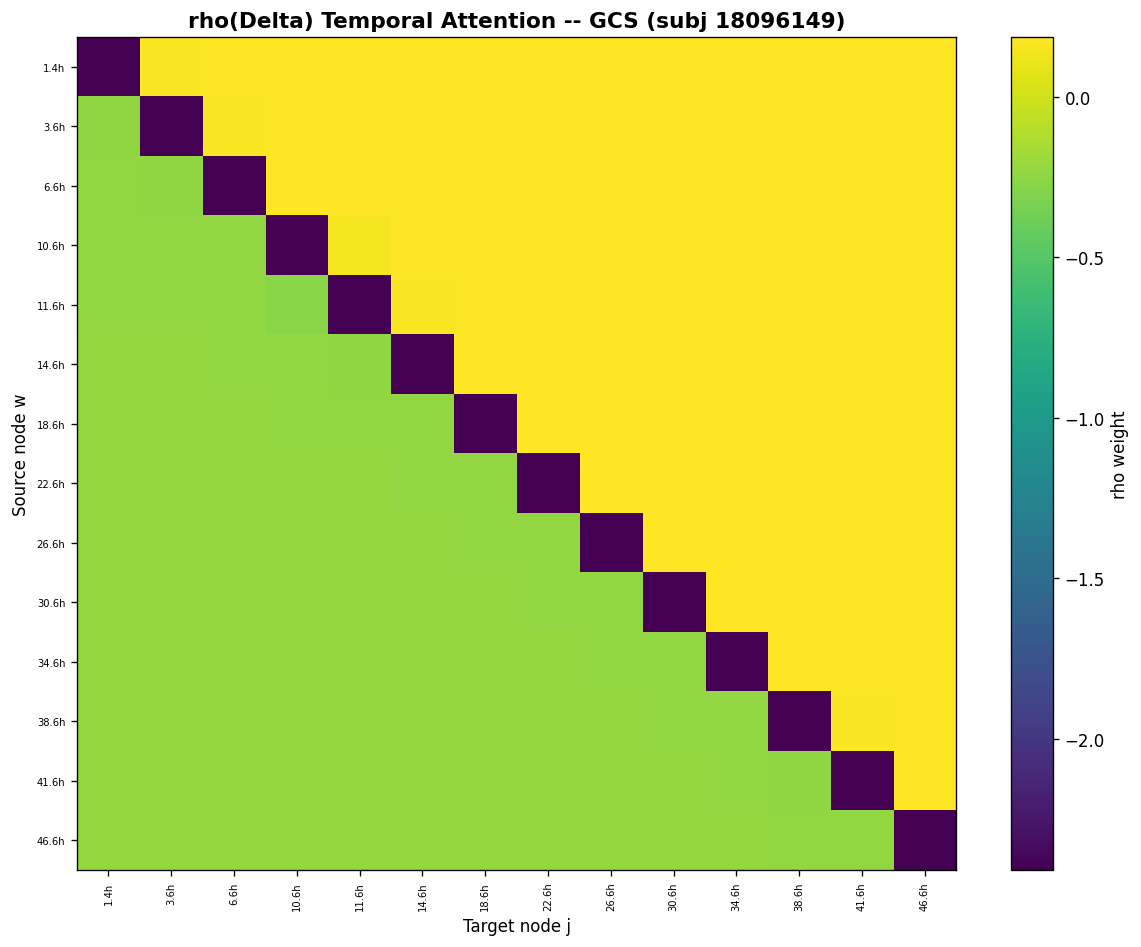

  [saved] exports/rho_18096149_HR.csv  (48 rows x 50 cols)


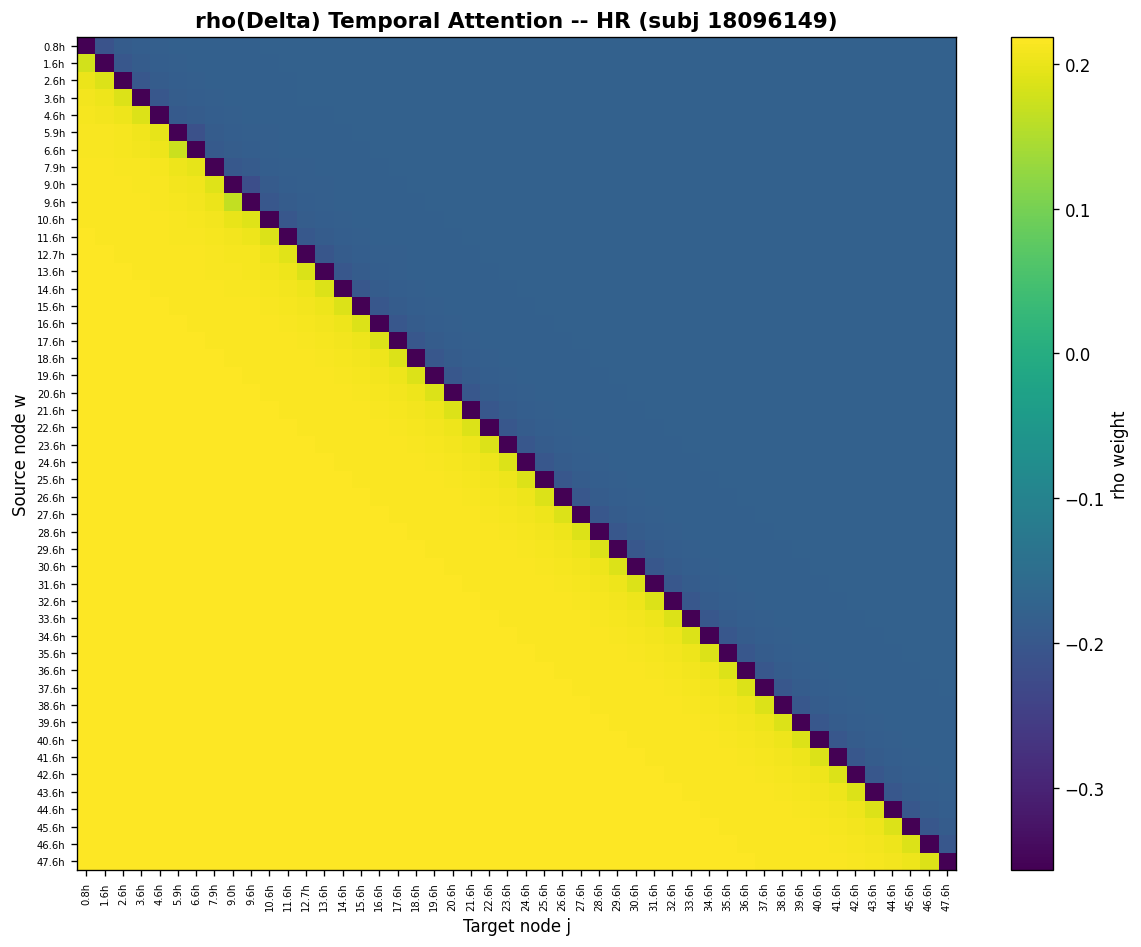


Survival case (idx 544, subject 13394639):
  [saved] exports/rho_13394639_GCS.csv  (18 rows x 20 cols)


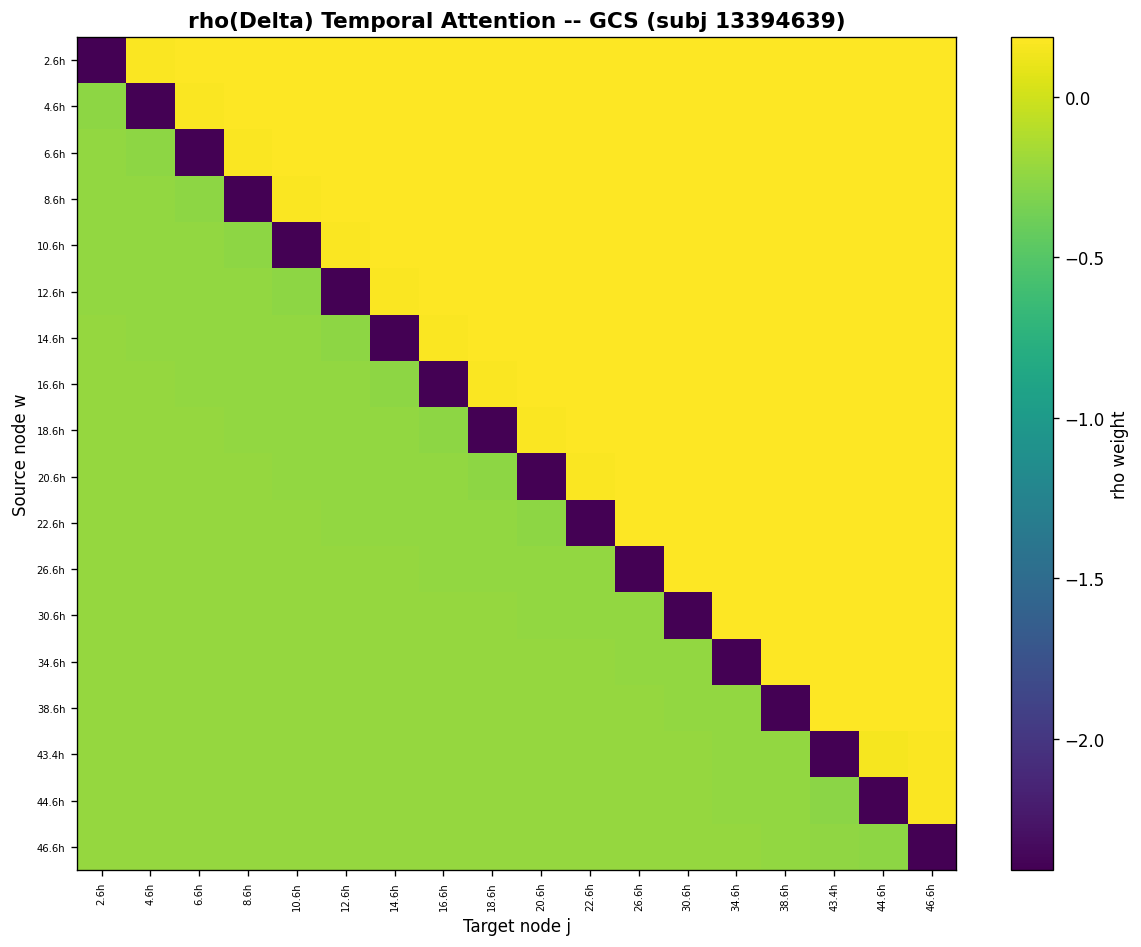

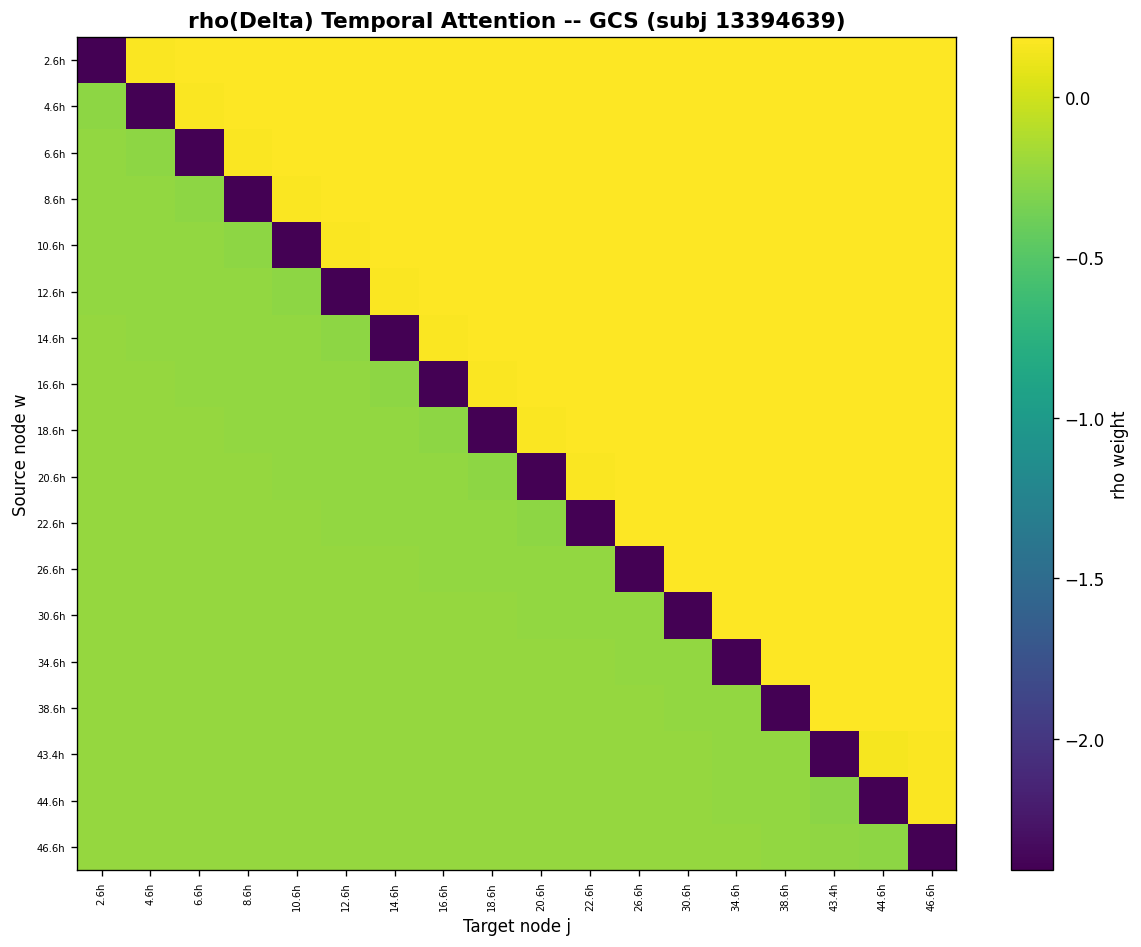

In [30]:
# ================================================================
# Temporal Attention (rho) Heatmaps -- SAME patients as the case study above
# ================================================================
print("=" * 60)
print("TEMPORAL ATTENTION HEATMAPS")
print("=" * 60)

print(f"\nMortality case (idx {i_mort}, subject {mort_subject_id}):")
plot_rho_heatmap(model, test_dataset[i_mort], DEVICE, biomarker="GCS",
                 raw_patient=test_patients_binned[i_mort], subject_id=mort_subject_id)
plot_rho_heatmap(model, test_dataset[i_mort], DEVICE, biomarker="HR",
                 raw_patient=test_patients_binned[i_mort], subject_id=mort_subject_id)

print(f"\nSurvival case (idx {i_surv}, subject {surv_subject_id}):")
plot_rho_heatmap(model, test_dataset[i_surv], DEVICE, biomarker="GCS",
                 raw_patient=test_patients_binned[i_surv], subject_id=surv_subject_id)

### Subset-Level Contribution Curves (PCA perturbation)

Following the paper: for each biomarker group we fit PCA, then progressively
perturb inputs along PC1 and record how the mean prediction shifts.

**Fix applied:** PCA is fit and perturbation applied **only on the dynamic
feature dims** (value + temporal context = indices `0..NUM_TEMPORAL`). The
previous version fit PCA on the full feature vector and perturbed every dim,
including one-hot ICU type, binary gender, and the frozen biomarker embedding --
which (a) let static variance dominate PC1 and (b) produced off-manifold inputs
(e.g. gender = 0.7, multiple ICU flags lit) where the model's response is
meaningless.

COMPUTING SUBSET-LEVEL CONTRIBUTION CURVES


  Baseline mean prediction: 0.2258 | 15 batches cached
  Fitting PCA per group (dynamic dims only)...
  Sweeping noise levels...


Groups: 100%|██████████| 27/27 [09:16<00:00, 20.59s/it]



Computed curves for 27 groups


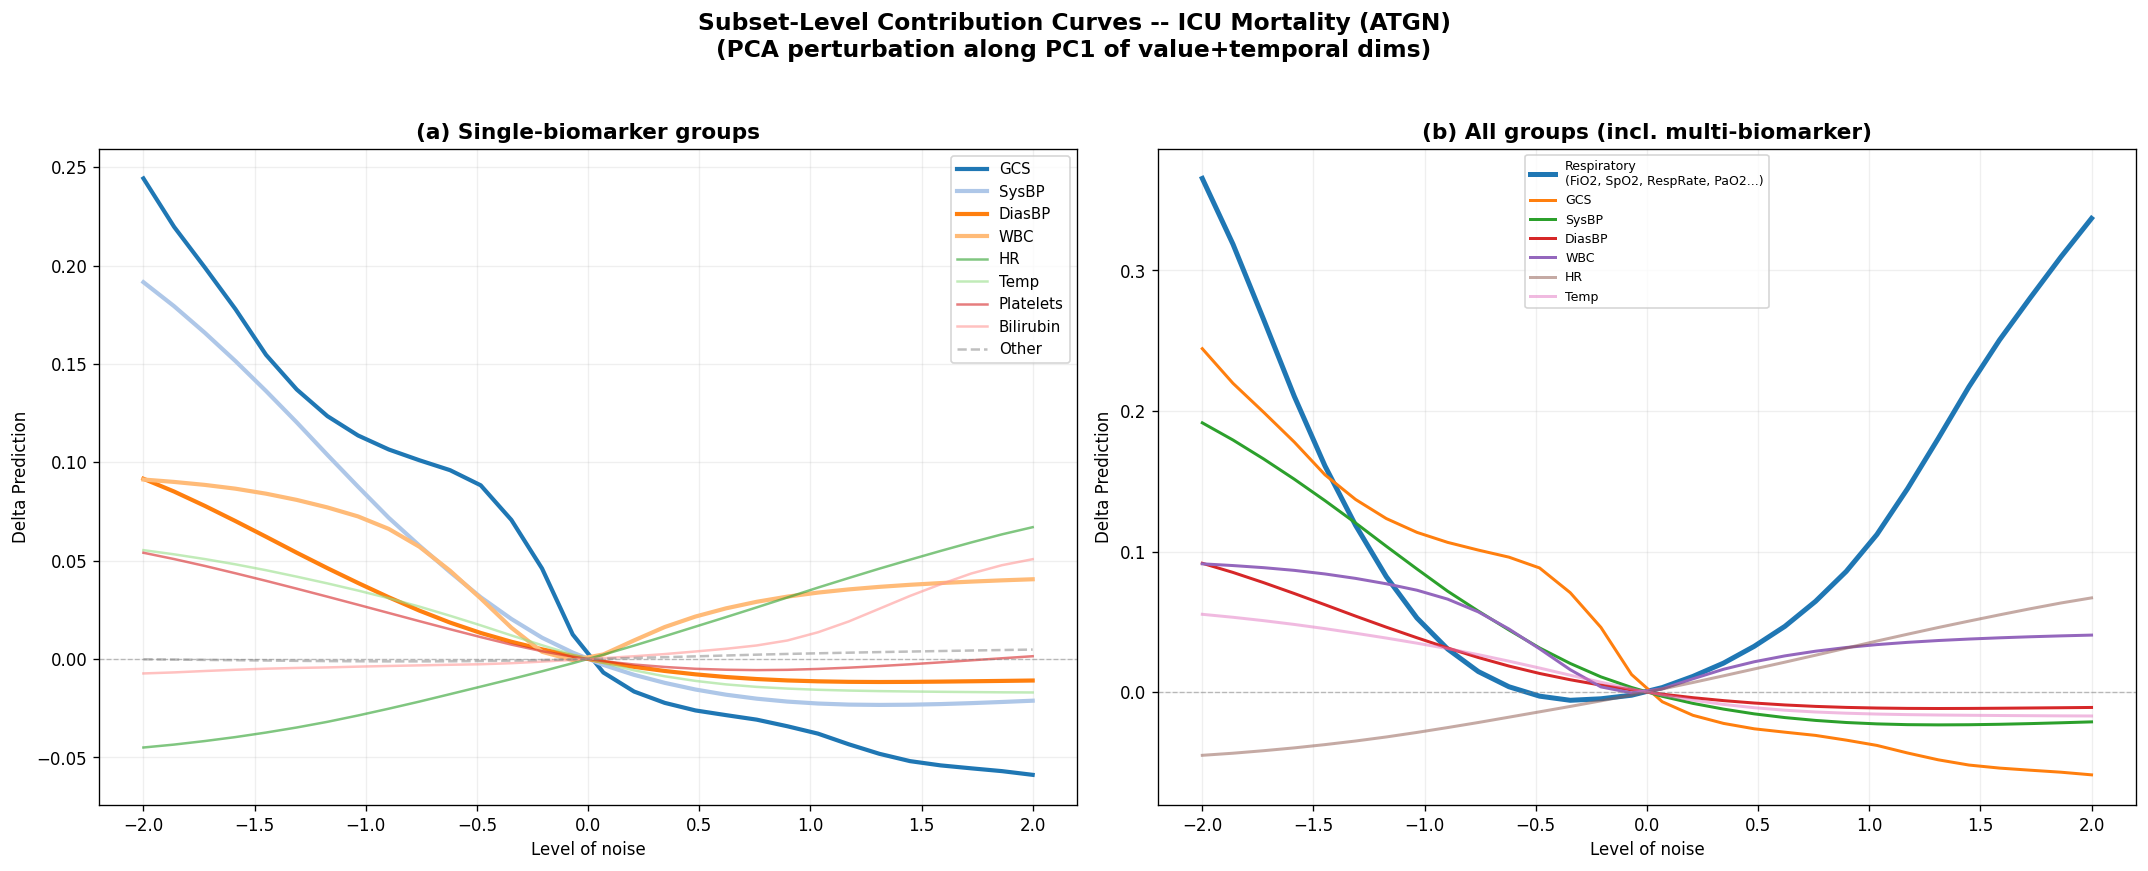

  [saved] exports/subset_contribution_curves.csv  (810 rows x 4 cols)
  [saved] exports/subset_contribution_summary.csv  (27 rows x 3 cols)

Top biomarker groups by max |Delta Prediction|:
      Respiratory (MULTI): max|Delta| = 0.3654
              GCS: max|Delta| = 0.2443
            SysBP: max|Delta| = 0.1915
           DiasBP: max|Delta| = 0.0916
              WBC: max|Delta| = 0.0912
               HR: max|Delta| = 0.0670
             Temp: max|Delta| = 0.0553
        Platelets: max|Delta| = 0.0540
        Bilirubin: max|Delta| = 0.0507
          Lactate: max|Delta| = 0.0462


In [31]:
from sklearn.decomposition import PCA

# Perturb only the dynamic dims: value (0) + temporal context (1..NUM_TEMPORAL).
PERTURB_DIMS = list(range(NUM_TEMPORAL + 1))  # e.g. [0, 1, 2]

@torch.no_grad()
def compute_subset_contribution_curves(model, loader, device, biomarker_groups, group_names,
                                        n_noise_levels=30, noise_range=(-2.0, 2.0),
                                        max_batches=15, perturb_dims=PERTURB_DIMS):
    """Subset-level PCA perturbation. PCA fit on perturb_dims only; perturbation
    is zero outside perturb_dims so categorical/embedding dims are untouched."""
    model.eval()
    biom_to_gi = {}
    for gi, group in enumerate(biomarker_groups):
        for b in group:
            biom_to_gi[b] = gi

    print("  Collecting baseline predictions and features...")
    cached_batches, baseline_preds = [], []
    features_by_group = defaultdict(list)
    for batch_idx, (data_batch, y_batch) in enumerate(tqdm(loader, desc="Caching", leave=False)):
        if batch_idx >= max_batches:
            break
        bs = y_batch.shape[0]
        logits = model(data_batch, bs)
        baseline_preds.append(torch.sigmoid(logits).cpu().numpy())
        cached_batches.append((data_batch, y_batch))
        for biom_name, data in data_batch.items():
            gi = biom_to_gi.get(biom_name)
            if gi is not None:
                # Only the dynamic columns feed PCA.
                features_by_group[gi].append(data['x_batch'][:, perturb_dims].numpy())
    baseline_mean = np.concatenate(baseline_preds).mean()
    print(f"  Baseline mean prediction: {baseline_mean:.4f} | {len(cached_batches)} batches cached")

    print("  Fitting PCA per group (dynamic dims only)...")
    pca_info = {}
    for gi in range(len(biomarker_groups)):
        if features_by_group[gi]:
            feats = np.concatenate(features_by_group[gi], axis=0)
            if feats.shape[0] >= 2:
                pca = PCA(n_components=1); pca.fit(feats)
                proj = pca.transform(feats).ravel()
                pca_info[gi] = {'pc1': pca.components_[0], 'proj_std': proj.std(),
                                'n_samples': feats.shape[0]}

    print("  Sweeping noise levels...")
    noise_levels = np.linspace(noise_range[0], noise_range[1], n_noise_levels)
    feature_dim = None
    for data_batch, _ in cached_batches:
        for _, data in data_batch.items():
            feature_dim = data['x_batch'].shape[1]; break
        if feature_dim is not None:
            break

    curves = {}
    for gi in tqdm(range(len(biomarker_groups)), desc="Groups"):
        if gi not in pca_info:
            continue
        pc1 = pca_info[gi]['pc1']            # length == len(perturb_dims)
        proj_std = pca_info[gi]['proj_std']
        bioms_in_group = set(biomarker_groups[gi])
        group_deltas = []
        for noise_level in noise_levels:
            # Full-width perturbation that is zero outside perturb_dims.
            full = np.zeros(feature_dim, dtype=np.float32)
            full[perturb_dims] = noise_level * proj_std * pc1
            perturbation = torch.tensor(full, dtype=torch.float32)
            perturbed_preds = []
            for data_batch, y_batch in cached_batches:
                bs = y_batch.shape[0]
                modified_batch = {}
                for biom_name, data in data_batch.items():
                    if biom_name in bioms_in_group:
                        modified_batch[biom_name] = {
                            'x_batch': data['x_batch'] + perturbation,
                            'dist_batch': data['dist_batch'],
                            'batch_vector': data['batch_vector'],
                        }
                    else:
                        modified_batch[biom_name] = data
                logits = model(modified_batch, bs)
                perturbed_preds.append(torch.sigmoid(logits).cpu().numpy())
            group_deltas.append(np.concatenate(perturbed_preds).mean() - baseline_mean)
        curves[gi] = group_deltas
    return noise_levels, curves, pca_info


print("=" * 60)
print("COMPUTING SUBSET-LEVEL CONTRIBUTION CURVES")
print("=" * 60)
noise_levels, curves, pca_info = compute_subset_contribution_curves(
    model, test_loader, DEVICE, biomarker_groups=BIOMARKER_GROUPS, group_names=GROUP_NAMES,
    n_noise_levels=30, noise_range=(-2.0, 2.0), max_batches=15)
print(f"\nComputed curves for {len(curves)} groups")

def max_effect(gi):
    return max(abs(d) for d in curves[gi])

singleton_gis = [gi for gi in curves if len(BIOMARKER_GROUPS[gi]) == 1]
multi_gis     = [gi for gi in curves if len(BIOMARKER_GROUPS[gi]) > 1]
singleton_gis.sort(key=max_effect, reverse=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
cmap1 = plt.cm.get_cmap('tab20', 20)
top_n = min(8, len(singleton_gis))
for rank, gi in enumerate(singleton_gis[:top_n]):
    lw = 2.5 if rank < 4 else 1.5; alpha = 1.0 if rank < 4 else 0.6
    ax1.plot(noise_levels, curves[gi], label=GROUP_NAMES[gi], linewidth=lw, alpha=alpha, color=cmap1(rank))
if len(singleton_gis) > top_n:
    other_mean = np.array([curves[gi] for gi in singleton_gis[top_n:]]).mean(axis=0)
    ax1.plot(noise_levels, other_mean, label="Other", linewidth=1.5, alpha=0.5, color='gray', linestyle='--')
ax1.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
ax1.set_xlabel("Level of noise"); ax1.set_ylabel("Delta Prediction")
ax1.set_title("(a) Single-biomarker groups", fontsize=13, fontweight='bold')
ax1.legend(fontsize=9, loc='best'); ax1.grid(True, alpha=0.2)

all_gis = multi_gis + singleton_gis[:6]
all_gis.sort(key=max_effect, reverse=True)
cmap2 = plt.cm.get_cmap('tab10', 10)
for rank, gi in enumerate(all_gis[:10]):
    name = GROUP_NAMES[gi]; group = BIOMARKER_GROUPS[gi]
    if len(group) > 1:
        name += "\n(" + ', '.join(group[:4]) + ('...' if len(group) > 4 else '') + ")"
        lw = 3.0
    else:
        lw = 1.8
    alpha = 1.0 if rank < 5 else 0.5
    ax2.plot(noise_levels, curves[gi], label=name, linewidth=lw, alpha=alpha, color=cmap2(rank))
ax2.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
ax2.set_xlabel("Level of noise"); ax2.set_ylabel("Delta Prediction")
ax2.set_title("(b) All groups (incl. multi-biomarker)", fontsize=13, fontweight='bold')
ax2.legend(fontsize=7.5, loc='best'); ax2.grid(True, alpha=0.2)
plt.suptitle("Subset-Level Contribution Curves -- ICU Mortality (ATGN)\n"
             "(PCA perturbation along PC1 of value+temporal dims)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "subset_contribution_curves.png"), dpi=150, bbox_inches='tight')
plt.show()

# EXPORT: full curves (long) + summary
long_rows = []
for gi, deltas in curves.items():
    is_multi = len(BIOMARKER_GROUPS[gi]) > 1
    for nl, d in zip(noise_levels, deltas):
        long_rows.append({"group": GROUP_NAMES[gi], "is_multi": is_multi,
                          "noise_level": float(nl), "delta_pred": float(d)})
export_df(pd.DataFrame(long_rows), "subset_contribution_curves.csv")

summary_rows = [{"group": GROUP_NAMES[gi], "is_multi": len(BIOMARKER_GROUPS[gi]) > 1,
                 "max_abs_delta": max_effect(gi)} for gi in curves]
summary_df = pd.DataFrame(summary_rows).sort_values("max_abs_delta", ascending=False)
export_df(summary_df, "subset_contribution_summary.csv")

print("\nTop biomarker groups by max |Delta Prediction|:")
for _, r in summary_df.head(10).iterrows():
    multi = " (MULTI)" if r['is_multi'] else ""
    print(f"  {r['group']:>15}{multi}: max|Delta| = {r['max_abs_delta']:.4f}")

## 10. Tests

Self-contained tests on synthetic data (no MIMIC, no GPU). The headline one is
`test_padding_regression`, which fails on the old forward pass and passes on the
fixed one. Run this cell after the model classes are defined; it does not depend
on the trained MIMIC model.

In [32]:
# ================================================================
# TEST SUITE -- synthetic, self-contained, runnable without MIMIC/GPU
# ================================================================
import numpy as _np
import torch as _torch

_TOL = 1e-4
_passed, _failed = [], []

def _run(test_fn):
    name = test_fn.__name__
    try:
        test_fn()
        _passed.append(name)
        print(f"  PASS  {name}")
    except Exception as e:
        _failed.append((name, repr(e)))
        print(f"  FAIL  {name}: {e!r}")

def _make_graph(T, seed=0):
    """Synthetic biomarker graph: node features [T, FEATURE_DIM], dist [T, T]."""
    g = _torch.Generator().manual_seed(seed)
    feats = _torch.randn(T, FEATURE_DIM, generator=g)
    times = _torch.arange(T, dtype=_torch.float32)
    dist = times[:, None] - times[None, :]
    return feats, dist

def _single_graph_logit_contrib(m, nf, dm, gnan_idx):
    """Channel-summed h_G for one biomarker graph in isolation (its logit share)."""
    bvec = _torch.zeros(nf.shape[0], dtype=_torch.long)
    h_G = m.gnans[gnan_idx](nf, dm, bvec)   # [1, repr]
    return float(h_G.sum().item())


def test_extgnan_shapes():
    gnan = EXTGNAN([[0, 1, 2], [3, 4]], hidden_channels=8, n_layers=2)
    out = gnan(_torch.randn(6, 5), _torch.zeros(6, 6), _torch.tensor([0, 0, 0, 1, 1, 1]))
    assert out.shape == (2, 5), out.shape
    assert gnan.repr_dim == 5

def test_deepset_is_sum_not_mean():
    ds = DeepSet(4, 4, 8, n_layers=2); ds.eval()
    x1 = _torch.ones(2, 1, 4)
    x2 = _torch.ones(4, 1, 4)
    # With SUM, doubling the set size (same elements) changes the pre-readout sum;
    # readout is linear, so outputs must differ (mean would give identical output).
    assert not _torch.allclose(ds(x1), ds(x2), atol=1e-6)

def test_collate_block_diagonal_and_batch_vector():
    nfA0, dmA0 = _make_graph(3, 1)
    nfA1, dmA1 = _make_graph(2, 2)
    b0 = ({"A": (nfA0, dmA0)}, _torch.tensor([0.0]))
    b1 = ({"A": (nfA1, dmA1)}, _torch.tensor([1.0]))
    out, y = collate_fn([b0, b1])
    db = out["A"]["dist_batch"]
    assert db.shape == (5, 5)
    # within-graph finite, cross-graph inf
    assert _torch.isfinite(db[:3, :3]).all() and _torch.isfinite(db[3:, 3:]).all()
    assert _torch.isinf(db[:3, 3:]).all() and _torch.isinf(db[3:, :3]).all()
    assert out["A"]["batch_vector"].tolist() == [0, 0, 0, 1, 1]
    assert y.tolist() == [0.0, 1.0]

def test_padding_regression():
    """Biomarker B present for patients 0 and 2 (gap at 1) in a batch of 4.
    The old forward zeroed patient 2's B embedding; the fix must match a
    per-graph reference exactly."""
    groups = [["A"], ["B"]]
    m = ATGN(groups, FEATURE_DIM, hidden_channels=8, n_layers=2,
             dropout=0.0, deepset_n_layers=2, device="cpu")
    m.eval()
    # Build 4 patients; all have A, only patients 0 and 2 have B.
    gdicts = []
    has_B = [True, False, True, False]
    for i in range(4):
        gd = {"A": _make_graph(3, seed=10 + i)}
        if has_B[i]:
            gd["B"] = _make_graph(4, seed=100 + i)
        gdicts.append(gd)
    batch = [(gd, _torch.tensor([0.0])) for gd in gdicts]
    out, _ = collate_fn(batch)
    logits = m(out, batch_dim=4).detach()

    giA = m.biomarker_to_gnan["A"]; giB = m.biomarker_to_gnan["B"]
    expected = []
    for i, gd in enumerate(gdicts):
        val = _single_graph_logit_contrib(m, gd["A"][0], gd["A"][1], giA)
        if "B" in gd:
            val += _single_graph_logit_contrib(m, gd["B"][0], gd["B"][1], giB)
        expected.append(val)
    expected = _torch.tensor(expected)
    assert _torch.allclose(logits, expected, atol=_TOL), \
        f"padding mismatch: got {logits.tolist()}, expected {expected.tolist()}"
    # Patient 2 (index 2) must include B's contribution -> differs from A-only.
    a_only_2 = _single_graph_logit_contrib(m, gdicts[2]["A"][0], gdicts[2]["A"][1], giA)
    assert abs(float(logits[2]) - a_only_2) > 1e-6, "patient 2's B contribution was dropped"

def test_attribution_identity_logit_equals_group_sum():
    groups = [["R1", "R2"], ["A"]]
    m = ATGN(groups, FEATURE_DIM, hidden_channels=8, n_layers=2,
             dropout=0.0, deepset_n_layers=2, device="cpu")
    m.eval()
    gd = {"R1": _make_graph(3, 1), "R2": _make_graph(4, 2), "A": _make_graph(2, 3)}
    inputs = {b: {"x_batch": nf, "dist_batch": dm,
                  "batch_vector": _torch.zeros(nf.shape[0], dtype=_torch.long)}
              for b, (nf, dm) in gd.items()}
    group_outputs = m(inputs, 1, return_group_outputs=True)
    total = float(group_outputs.sum().item())
    logit = float(m(inputs, 1).item())
    assert abs(total - logit) < _TOL, f"{total} != {logit}"

def test_singleton_node_attribution_is_exact():
    groups = [["R1", "R2"], ["A"]]
    m = ATGN(groups, FEATURE_DIM, hidden_channels=8, n_layers=2,
             dropout=0.0, deepset_n_layers=2, device="cpu")
    m.eval()
    nf, dm = _make_graph(5, 7)
    gi = m.biomarker_to_gnan["A"]
    bvec = _torch.zeros(nf.shape[0], dtype=_torch.long)
    h_G, node_emb = m.gnans[gi](nf, dm, bvec, return_node_embeddings=True)
    node_contribs = node_emb.sum(dim=-1)            # Eq. 6 per node
    assert abs(float(node_contribs.sum()) - float(h_G.sum())) < _TOL

def test_metrics_perfect_separation():
    labels = _np.array([0, 0, 1, 1])
    probs = _np.array([0.1, 0.2, 0.8, 0.9])
    mtr = compute_full_metrics(labels, probs)
    assert abs(mtr['auroc'] - 1.0) < 1e-9
    assert abs(mtr['auprc'] - 1.0) < 1e-9
    assert abs(mtr['accuracy'] - 1.0) < 1e-9

def test_dataset_zscore_normalization():
    enc = OneHotEncoder(["HR"])
    emb = OneHotEmbedder(input_dim=1, output_dim=BIOM_EMBED_DIM)
    patient = {"patient_id": 1, "stay_id": 1, "label": 0,
               "static": {"age": 50, "gender": 1, "icu_type": 0},
               "timeseries": {"HR": [(0.0, 100.0), (1.0, 120.0)]}}
    stats = {"HR": {"mean": 100.0, "std": 10.0}}
    ds = MIMICIV_GraphDataset([patient], ["HR"], enc, emb, biomarker_stats=stats)
    gd, _ = ds[0]
    vals = gd["HR"][0][:, 0].numpy()   # value column, z-scored
    assert _np.allclose(vals, [0.0, 2.0], atol=1e-5), vals

def test_export_df_writes_file():
    p = export_df(pd.DataFrame({"a": [1, 2], "b": [3, 4]}), "test_unit_export.csv")
    assert os.path.exists(p)
    back = pd.read_csv(p)
    assert list(back.columns) == ["a", "b"] and len(back) == 2

def test_platt_calibration_monotone():
    from sklearn.linear_model import LogisticRegression
    rng = _np.random.RandomState(0)
    x = rng.rand(200)
    y = (x + 0.1 * rng.randn(200) > 0.5).astype(int)
    lr = LogisticRegression(C=1e10, max_iter=1000).fit(x.reshape(-1, 1), y)
    grid = _np.linspace(0, 1, 50).reshape(-1, 1)
    pr = lr.predict_proba(grid)[:, 1]
    assert _np.all(_np.diff(pr) >= -1e-9), "Platt scaling must be monotone in input"


for _t in [test_extgnan_shapes, test_deepset_is_sum_not_mean,
           test_collate_block_diagonal_and_batch_vector, test_padding_regression,
           test_attribution_identity_logit_equals_group_sum,
           test_singleton_node_attribution_is_exact, test_metrics_perfect_separation,
           test_dataset_zscore_normalization, test_export_df_writes_file,
           test_platt_calibration_monotone]:
    _run(_t)

print("\n" + "=" * 50)
print(f"TESTS: {len(_passed)} passed, {len(_failed)} failed")
print("=" * 50)
assert not _failed, f"Failing tests: {[n for n, _ in _failed]}"

  PASS  test_extgnan_shapes
  PASS  test_deepset_is_sum_not_mean
  PASS  test_collate_block_diagonal_and_batch_vector
  PASS  test_padding_regression
  PASS  test_attribution_identity_logit_equals_group_sum
  PASS  test_singleton_node_attribution_is_exact
  PASS  test_metrics_perfect_separation
  PASS  test_dataset_zscore_normalization
  [saved] exports/test_unit_export.csv  (2 rows x 2 cols)
  PASS  test_export_df_writes_file
  PASS  test_platt_calibration_monotone

TESTS: 10 passed, 0 failed


In [33]:
# ================================================================
# Export manifest -- everything written to EXPORT_DIR this run
# ================================================================
manifest_df = pd.DataFrame(_EXPORT_MANIFEST).drop_duplicates(subset=["file"], keep="last")
manifest_df = manifest_df.sort_values("file").reset_index(drop=True)
manifest_df.to_csv(os.path.join(EXPORT_DIR, "_manifest.csv"), index=False)
print(f"Exported {len(manifest_df)} CSV/figure-data files to {EXPORT_DIR}/")
print(manifest_df.to_string(index=False))

Exported 23 CSV/figure-data files to exports/
                                       file   rows  cols
                      calibration_brier.csv      1     2
                       confusion_matrix.csv      2     2
               global_node_attributions.csv 108936     7
            group_importance_by_outcome.csv     27     4
           group_importance_per_patient.csv  68473     4
node_attribution_13394639_SURVIVED_long.csv    189     5
node_attribution_13394639_SURVIVED_wide.csv     21    51
    node_attribution_18096149_DIED_long.csv    317     5
    node_attribution_18096149_DIED_wide.csv     25    51
                patient_13394639_hourly.csv     22    51
                patient_18096149_hourly.csv     30    51
                               pr_curve.csv   3079     3
                    reliability_diagram.csv     19     3
                       rho_13394639_GCS.csv     18    20
                       rho_18096149_GCS.csv     14    16
                        rho_18096149_HR.cs

## end